## Imports

In [136]:
import pandas as pd
import numpy as np
from numpy.typing import ArrayLike
import matplotlib.pyplot as plt 
from tqdm import tqdm

from sklearn.base import clone

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, cross_validate

from sklearn.feature_selection import f_classif, RFE

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, PowerTransformer, PolynomialFeatures
from sklearn.compose import ColumnTransformer

from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, IsolationForest

from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, \
                            f1_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay

from sklearn.covariance import EllipticEnvelope

from sklearn.decomposition import PCA

from joblib import load

from shap import TreeExplainer
from shap.plots import beeswarm

## Data Preprocessing

In [137]:
# Load and preview data
df = pd.read_csv('OnlineNewsPopularity.csv')
df.head()

,url,timedelta,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares
0,http://mashable.com/2013/01/07/amazon-instant-...,731.0,12.0,219.0,0.663594,1.0,0.815385,4.0,2.0,1.0,...,0.100000,0.7,-0.350000,-0.600,-0.200000,0.500000,-0.187500,0.000000,0.187500,593
1,http://mashable.com/2013/01/07/ap-samsung-spon...,731.0,9.0,255.0,0.604743,1.0,0.791946,3.0,1.0,1.0,...,0.033333,0.7,-0.118750,-0.125,-0.100000,0.000000,0.000000,0.500000,0.000000,711
2,http://mashable.com/2013/01/07/apple-40-billio...,731.0,9.0,211.0,0.575130,1.0,0.663866,3.0,1.0,1.0,...,0.100000,1.0,-0.466667,-0.800,-0.133333,0.000000,0.000000,0.500000,0.000000,1500
3,http://mashable.com/2013/01/07/astronaut-notre...,731.0,9.0,531.0,0.503788,1.0,0.665635,9.0,0.0,1.0,...,0.136364,0.8,-0.369697,-0.600,-0.166667,0.000000,0.000000,0.500000,0.000000,1200
4,http://mashable.com/2013/01/07/att-u-verse-apps/,731.0,13.0,1072.0,0.415646,1.0,0.540890,19.0,19.0,20.0,...,0.033333,1.0,-0.220192,-0.500,-0.050000,0.454545,0.136364,0.045455,0.136364,505


In [138]:
# Remove white space from column names
df.columns = df.columns.str.strip()

In [140]:
# Convert boolean columns to boolean
bool_columns = ['data_channel_is_lifestyle', 'data_channel_is_entertainment', 'data_channel_is_bus', 'data_channel_is_socmed',
                'data_channel_is_tech', 'data_channel_is_world', 'weekday_is_monday', 'weekday_is_tuesday', 'weekday_is_wednesday',
                'weekday_is_thursday', 'weekday_is_friday', 'weekday_is_saturday', 'weekday_is_sunday', 'is_weekend']

# Get numerical columns
non_bool_columns = [column for column in df.columns if df[column].dtype == float]

In [141]:
# Get median of shares
df['shares'].median()

1400.0

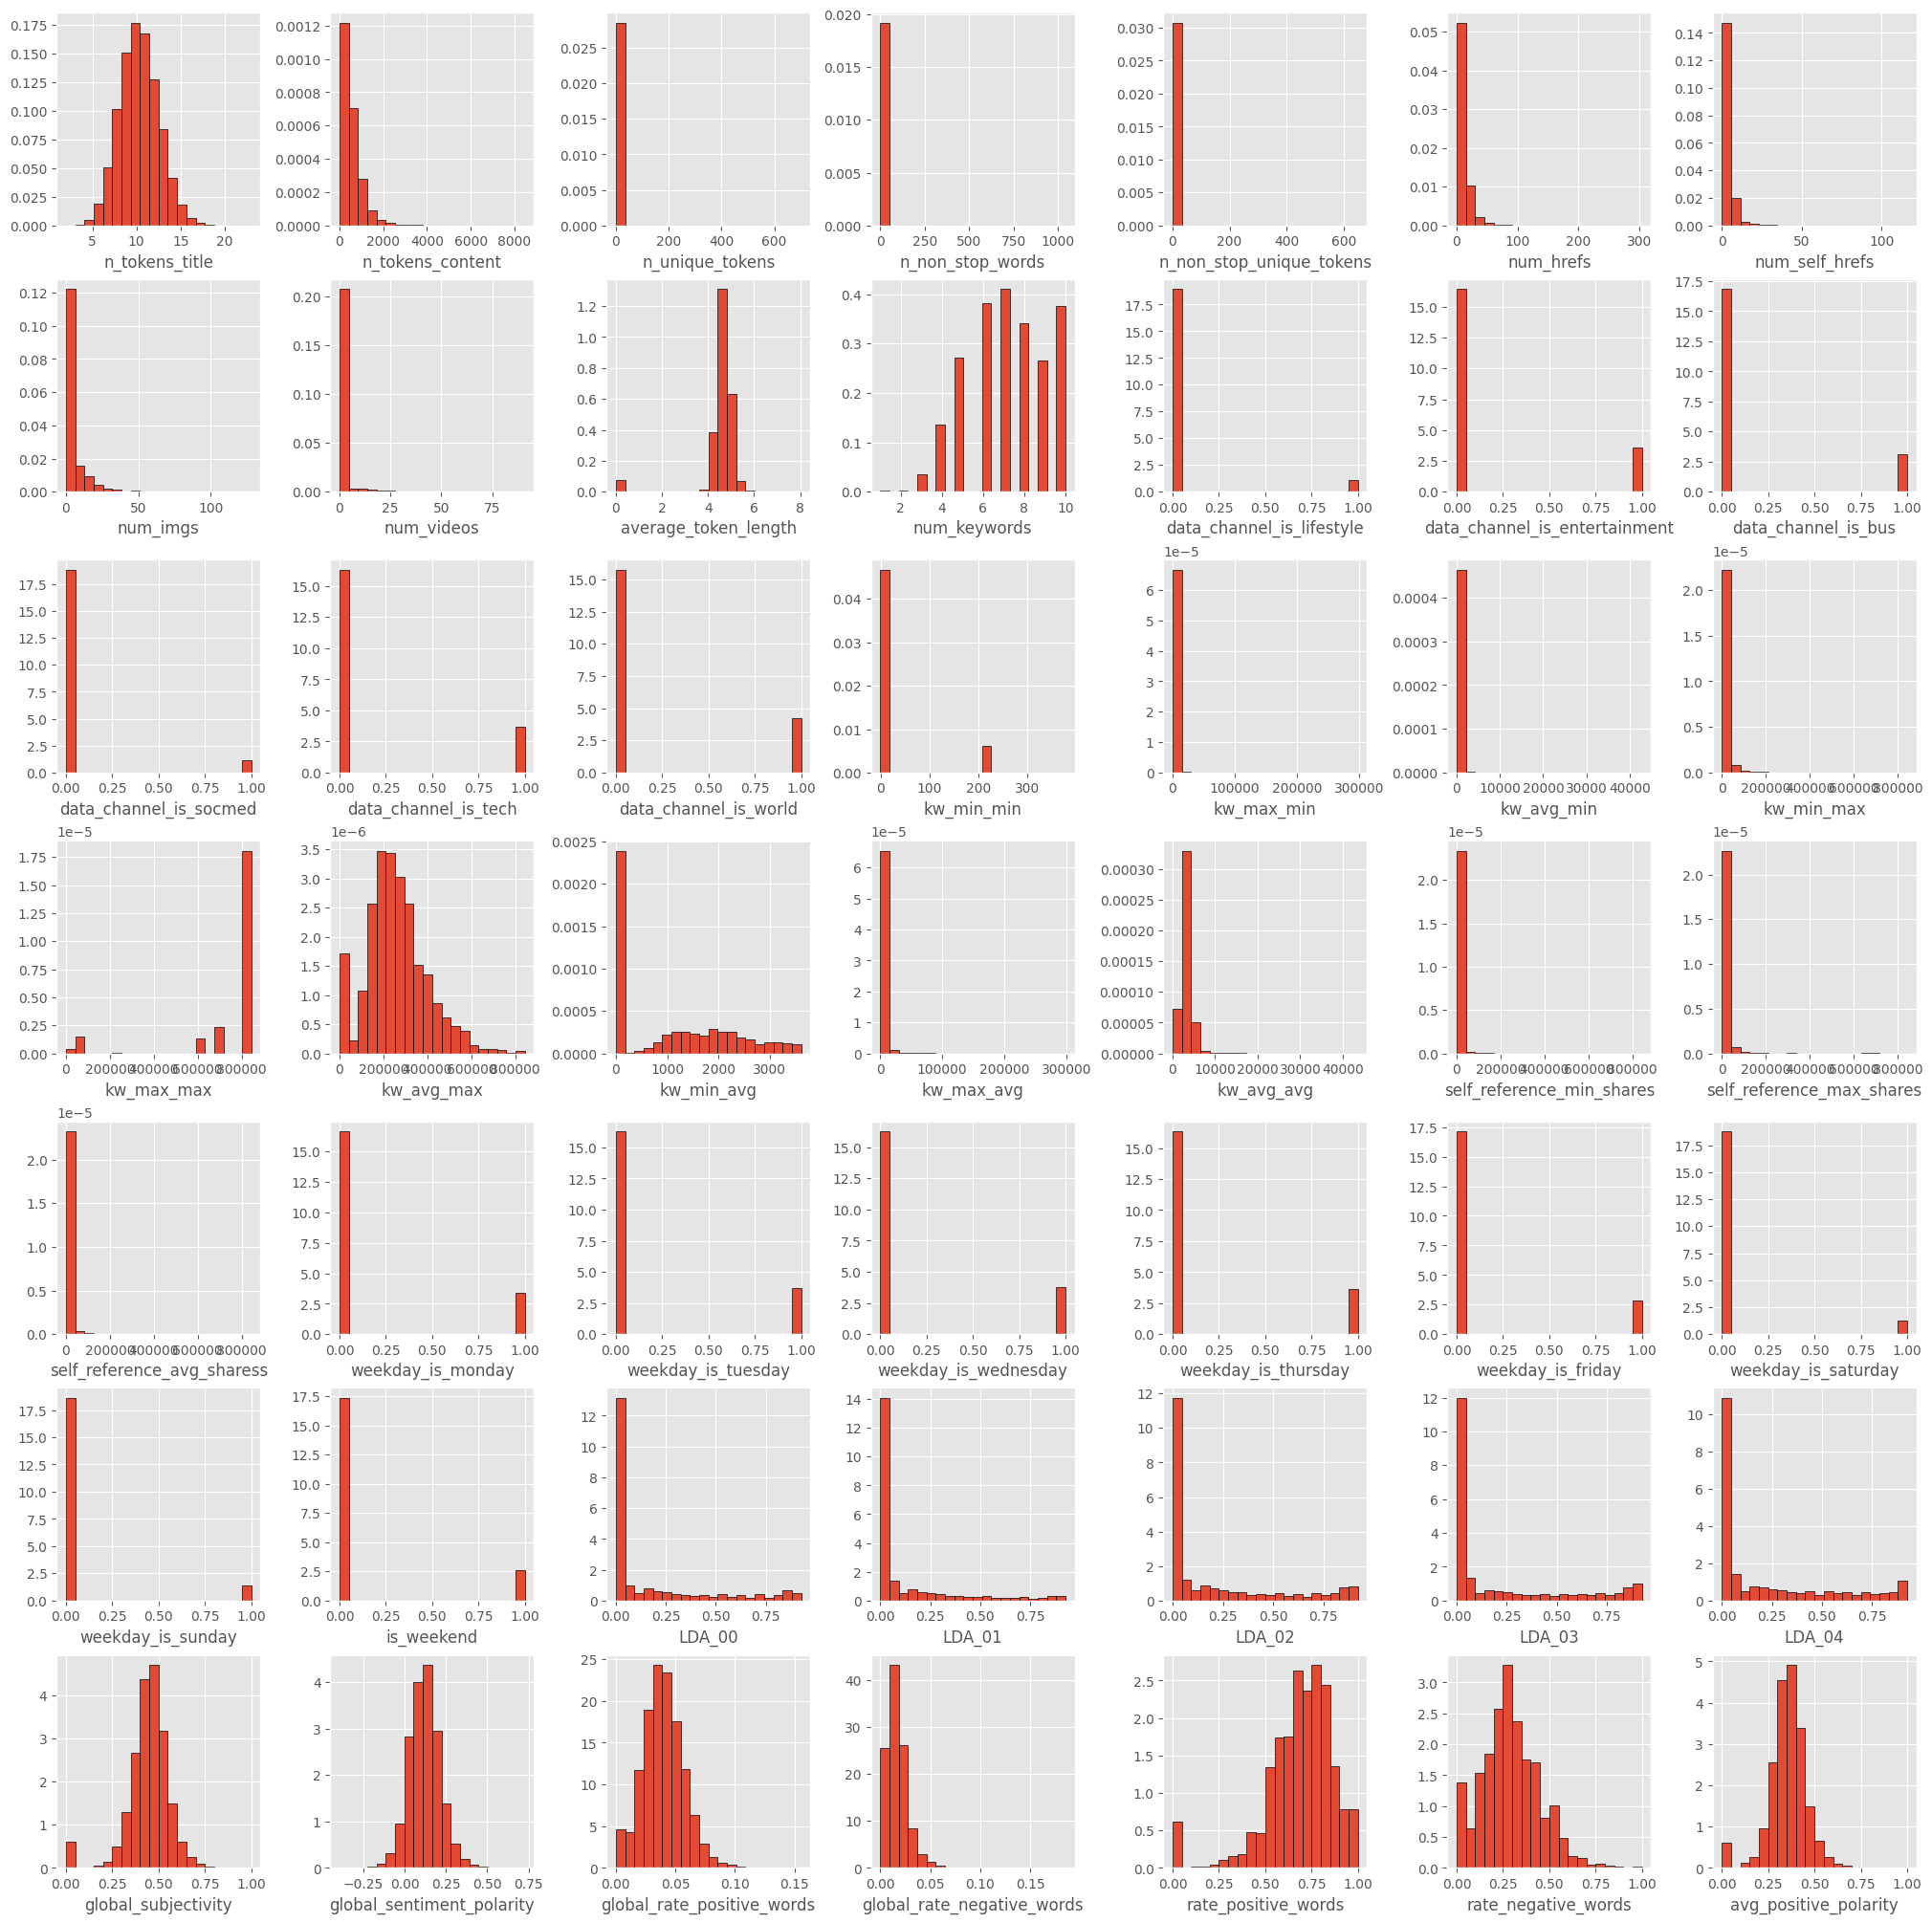

In [142]:
# Make histogram for each numerical feature
plt.style.use('ggplot')
fig, axes = plt.subplots(7, 7, figsize=(20, 20), constrained_layout=True)

for feature, ax in zip(non_bool_columns[1:], axes.ravel()):
    ax.hist(df[feature], bins=20, edgecolor='k', density=True)
    ax.set_xlabel(xlabel=feature)


In [143]:
# Split to feature and target datasets
X = df.drop(['shares', 'url'], axis=1)
y = df['shares'] >= 1400

# Change the datatype of the boolean columns to boolean
X[bool_columns] = X[bool_columns].astype(bool)


In [144]:
# Get skewed features
skewed_columns = ['n_tokens_content', 'num_hrefs', 'num_self_hrefs', 'num_imgs', 'num_videos', 'kw_min_avg', 'kw_avg_avg',
                  'LDA_00', 'LDA_01', 'LDA_02', 'LDA_03', 'LDA_04', 'global_rate_negative_words']
non_skewed_columns = [c for c in X.columns if c not in skewed_columns]
non_skewed_non_bool_columns = [c for c in X.columns if c not in skewed_columns and c not in bool_columns]

In [145]:
# Split data into train and test datasets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)

## Choosing the best scaling method

### Find the best scaling method for the LinearSVC model

In [146]:
# Define summary making function
def make_summary(models: list,
                 X_train: ArrayLike = X_train,
                 X_test: ArrayLike = X_test,
                 y_train: ArrayLike = y_train,
                 y_test: ArrayLike = y_test,
                 index: list[str] = None,
                 sort: bool = True) -> pd.DataFrame:
    
    # Define necessary lists
    train_accuracy = []
    test_accuracy = []
    mean_cv_accuracy = []

    precision = []
    recall = []
    f1 = []
    mean_cv_auc = []
    test_auc = []

    # Get accuracy, precision, recall f1-score, and AUC for all models (about 1 minute)
    for i, model in enumerate(models):
        # Get predictions
        train_preds = model.predict(X=X_train)
        test_preds = model.predict(X=X_test)
        cv_results = cross_validate(estimator=model,
                                    X=X_train, y=y_train,
                                    cv=5,
                                    scoring=['roc_auc', 'accuracy'])

        # Get all metrics
        train_accuracy.append(accuracy_score(y_true=y_train, y_pred=train_preds))
        test_accuracy.append(accuracy_score(y_true=y_test, y_pred=test_preds))
        mean_cv_accuracy.append(cv_results['test_accuracy'].mean())

        precision.append(precision_score(y_true=y_test, y_pred=test_preds))
        recall.append(recall_score(y_true=y_test, y_pred=test_preds))
        f1.append(f1_score(y_true=y_test, y_pred=test_preds))
        mean_cv_auc.append(cv_results['test_roc_auc'].mean())
        test_auc.append(roc_auc_score(y_true=y_test, y_score=test_preds))

    # Create summary dictionary
    data = {
        'Train Accuracy' : train_accuracy,
        'Test Accuracy' : test_accuracy,
        'Mean CV Accuracy' : mean_cv_accuracy,

        'Precision' : precision,
        'Recall' : recall,
        'F1' : f1,
        'Mean CV AUC' : mean_cv_auc,
        'Test AUC' : test_auc,
    }

    # Create summary dataframe
    summary = pd.DataFrame(data=data, index=index)

    # Return sorted summary if desired
    if sort:
        return summary.round(2).sort_values(by=['Mean CV AUC', 'Test AUC', 'Mean CV Accuracy'], ascending=False)
    
    # Return summary
    return summary
    

In [147]:
# Define pipelines to test the effect of different scaling methods
# Unscaled model
unscaled_svc = LinearSVC(random_state=0)

# Standardise all features
standardised_svc = Pipeline(steps=[
    ('standardiser', StandardScaler()),
    ('classifier', LinearSVC(random_state=0))
])

# Standardise only non-boolean features
standardised_non_bool_svc = Pipeline(steps=[
    ('transformer', ColumnTransformer(transformers=[('standardiser', StandardScaler(), non_bool_columns)],
                                      remainder='passthrough')),
    ('classifier', LinearSVC(random_state=0))
])

# Power transform skewed features and standardise all rest of the feastures
pt_skewed_all_standardised_svc = Pipeline(steps=[
    ('transformer', ColumnTransformer(transformers=[
                                      ('power_transform', PowerTransformer(), skewed_columns),
                                      ('standardiser', StandardScaler(), non_skewed_columns)])),
    ('classifier', LinearSVC(random_state=0))
])

# Power transform skewed features and standardise only non-bool features
pt_skewed_non_bool_standardised_svc = Pipeline(steps=[
    ('transformer', ColumnTransformer(transformers=[
                                      ('power_transform', PowerTransformer(), skewed_columns),
                                      ('standardiser', StandardScaler(), non_skewed_non_bool_columns)],
                                      remainder='passthrough')),
    ('classifier', LinearSVC(random_state=0))
])

# Minmax scale all features 
minmax_svc = Pipeline(steps=[
    ('scaler', MinMaxScaler()),
    ('classifier', LinearSVC(random_state=0))
])

# Minmax scale only non-boolean features
minmax_non_bool_svc = Pipeline(steps=[
    ('transformer', ColumnTransformer(transformers=[('scaler', MinMaxScaler(), non_bool_columns)],
                                      remainder='passthrough')),
    ('classifier', LinearSVC(random_state=0))
])

# Power transform skewed features and minmax scale all rest of the feastures
pt_skewed_all_minmax_svc = Pipeline(steps=[
    ('transformer', ColumnTransformer(transformers=[
                                      ('power_transform', PowerTransformer(), skewed_columns),
                                      ('scaler', MinMaxScaler(), non_skewed_columns)])),
    ('classifier', LinearSVC(random_state=0))
])

# Power transform skewed features and minmax scale only non-bool features
pt_skewed_non_bool_minmax_svc = Pipeline(steps=[
    ('transformer', ColumnTransformer(transformers=[
                                      ('power_transform', PowerTransformer(), skewed_columns),
                                      ('scaler', MinMaxScaler(), non_skewed_non_bool_columns)],
                                      remainder='passthrough')),
    ('classifier', LinearSVC(random_state=0))
])

In [ ]:
# Fit all pipelines on non-stratified split (about 45 seconds)
unscaled_svc.fit(X=X_train, y=y_train)

standardised_svc.fit(X=X_train, y=y_train)
standardised_non_bool_svc.fit(X=X_train, y=y_train)

pt_skewed_all_standardised_svc.fit(X=X_train, y=y_train)
pt_skewed_non_bool_standardised_svc.fit(X=X_train, y=y_train)

minmax_svc.fit(X=X_train, y=y_train)
minmax_non_bool_svc.fit(X=X_train, y=y_train)

pt_skewed_all_minmax_svc.fit(X=X_train, y=y_train)
pt_skewed_non_bool_minmax_svc.fit(X=X_train, y=y_train)

In [ ]:
# Create necessary lists
pipelines_svc = [unscaled_svc, standardised_svc, standardised_non_bool_svc,
             pt_skewed_all_standardised_svc, pt_skewed_non_bool_standardised_svc,
             minmax_svc, minmax_non_bool_svc, pt_skewed_all_minmax_svc, pt_skewed_non_bool_minmax_svc]

index_svc = ['unscaled_svc', 'standardised_svc', 'standardised_non_bool_svc', 'pt_skewed_all_standardised_svc',
             'pt_skewed_non_bool_standardised_svc', 'minmax_svc', 'minmax_non_bool_svc', 'pt_skewed_all_minmax_svc',
             'pt_skewed_non_bool_minmax_svc']

# Make summary for all svc pipelines (about 3 minutes)
summary_svc = make_summary(models=pipelines_svc,
                           X_train=X_train,
                           X_test=X_test,
                           y_train=y_train,
                           y_test=y_test,
                           index=index_svc)

In [150]:
# View summary
summary_svc

,Train Accuracy,Test Accuracy,Mean CV Accuracy,Precision,Recall,F1,Mean CV AUC,Test AUC
standardised_svc,0.66,0.65,0.66,0.66,0.69,0.68,0.71,0.65
standardised_non_bool_svc,0.66,0.65,0.66,0.66,0.69,0.68,0.71,0.65
pt_skewed_all_standardised_svc,0.66,0.65,0.66,0.66,0.70,0.68,0.71,0.65
pt_skewed_non_bool_standardised_svc,0.66,0.65,0.66,0.66,0.70,0.68,0.71,0.65
pt_skewed_all_minmax_svc,0.66,0.65,0.66,0.66,0.70,0.68,0.71,0.65
pt_skewed_non_bool_minmax_svc,0.66,0.65,0.66,0.66,0.70,0.68,0.71,0.65
minmax_svc,0.66,0.64,0.65,0.66,0.69,0.67,0.70,0.64
minmax_non_bool_svc,0.66,0.64,0.65,0.66,0.69,0.67,0.70,0.64
unscaled_svc,0.54,0.53,0.51,0.53,0.99,0.69,0.52,0.50


### Find the best scaling method for the LogisticRegression model

In [151]:
# Define pipelines to test the effect of different scaling methods
# Unscaled model
unscaled_logreg = LogisticRegression(random_state=0)

# Standardise all features
standardised_logreg = Pipeline(steps=[
    ('standardiser', StandardScaler()),
    ('classifier', LogisticRegression(random_state=0))
])

# Standardise only non-boolean features
standardised_non_bool_logreg = Pipeline(steps=[
    ('transformer', ColumnTransformer(transformers=[('standardiser', StandardScaler(), non_bool_columns)],
                                      remainder='passthrough')),
    ('classifier', LogisticRegression(random_state=0))
])

# Power transform skewed features and standardise all rest of the feastures
pt_skewed_all_standardised_logreg = Pipeline(steps=[
    ('transformer', ColumnTransformer(transformers=[
                                      ('power_transform', PowerTransformer(), skewed_columns),
                                      ('standardiser', StandardScaler(), non_skewed_columns)])),
    ('classifier', LogisticRegression(random_state=0))
])

# Power transform skewed features and standardise only non-bool features
pt_skewed_non_bool_standardised_logreg = Pipeline(steps=[
    ('transformer', ColumnTransformer(transformers=[
                                      ('power_transform', PowerTransformer(), skewed_columns),
                                      ('standardiser', StandardScaler(), non_skewed_non_bool_columns)],
                                      remainder='passthrough')),
    ('classifier', LogisticRegression(random_state=0))
])

# Minmax scale all features 
minmax_logreg = Pipeline(steps=[
    ('scaler', MinMaxScaler()),
    ('classifier', LogisticRegression(random_state=0))
])

# Minmax scale only non-boolean features
minmax_non_bool_logreg = Pipeline(steps=[
    ('transformer', ColumnTransformer(transformers=[('scaler', MinMaxScaler(), non_bool_columns)],
                                      remainder='passthrough')),
    ('classifier', LogisticRegression(random_state=0))
])

# Power transform skewed features and minmax scale all rest of the feastures
pt_skewed_all_minmax_logreg = Pipeline(steps=[
    ('transformer', ColumnTransformer(transformers=[
                                      ('power_transform', PowerTransformer(), skewed_columns),
                                      ('scaler', MinMaxScaler(), non_skewed_columns)])),
    ('classifier', LogisticRegression(random_state=0))
])

# Power transform skewed features and minmax scale only non-bool features
pt_skewed_non_bool_minmax_logreg = Pipeline(steps=[
    ('transformer', ColumnTransformer(transformers=[
                                      ('power_transform', PowerTransformer(), skewed_columns),
                                      ('scaler', MinMaxScaler(), non_skewed_non_bool_columns)],
                                      remainder='passthrough')),
    ('classifier', LogisticRegression(random_state=0))
])

In [ ]:
# Fit all pipelines on non-stratified split (about 5 seconds)
unscaled_logreg.fit(X=X_train, y=y_train)

standardised_logreg.fit(X=X_train, y=y_train)
standardised_non_bool_logreg.fit(X=X_train, y=y_train)

pt_skewed_all_standardised_logreg.fit(X=X_train, y=y_train)
pt_skewed_non_bool_standardised_logreg.fit(X=X_train, y=y_train)

minmax_logreg.fit(X=X_train, y=y_train)
minmax_non_bool_logreg.fit(X=X_train, y=y_train)

pt_skewed_all_minmax_logreg.fit(X=X_train, y=y_train)
pt_skewed_non_bool_minmax_logreg.fit(X=X_train, y=y_train)

In [ ]:
# Create necessary lists
pipelines_logreg = [unscaled_logreg, standardised_logreg, standardised_non_bool_logreg, pt_skewed_all_standardised_logreg,
                    pt_skewed_non_bool_standardised_logreg, minmax_logreg, minmax_non_bool_logreg, pt_skewed_all_minmax_logreg,
                    pt_skewed_non_bool_minmax_logreg]

index_logreg = ['unscaled_logreg', 'standardised_logreg', 'standardised_non_bool_logreg',
                'pt_skewed_all_standardised_logreg', 'pt_skewed_non_bool_standardised_logreg', 'minmax_logreg',
                'minmax_non_bool_logreg', 'pt_skewed_all_minmax_logreg', 'pt_skewed_non_bool_minmax_logreg']

# Create summary dataframe (about 20 seconds)
summary_logreg = make_summary(models=pipelines_logreg, index=index_logreg)

In [154]:
# View summary
summary_logreg

,Train Accuracy,Test Accuracy,Mean CV Accuracy,Precision,Recall,F1,Mean CV AUC,Test AUC
pt_skewed_all_standardised_logreg,0.66,0.65,0.66,0.66,0.70,0.68,0.71,0.65
pt_skewed_non_bool_standardised_logreg,0.66,0.65,0.66,0.66,0.70,0.68,0.71,0.65
pt_skewed_all_minmax_logreg,0.66,0.65,0.66,0.66,0.70,0.68,0.71,0.65
pt_skewed_non_bool_minmax_logreg,0.66,0.65,0.66,0.66,0.70,0.68,0.71,0.65
standardised_logreg,0.66,0.65,0.65,0.66,0.69,0.68,0.71,0.65
standardised_non_bool_logreg,0.66,0.65,0.65,0.66,0.69,0.68,0.71,0.65
minmax_logreg,0.65,0.64,0.65,0.65,0.70,0.67,0.70,0.64
minmax_non_bool_logreg,0.65,0.64,0.65,0.65,0.70,0.67,0.70,0.64
unscaled_logreg,0.59,0.59,0.59,0.60,0.69,0.64,0.62,0.59


### Find the best scaling method for the KNeighborsClassifier model

In [155]:
# Define pipelines to test the effect of different scaling methods
# Unscaled model
unscaled_knc = KNeighborsClassifier()

# Standardise all features
standardised_knc = Pipeline(steps=[
    ('standardiser', StandardScaler()),
    ('classifier', KNeighborsClassifier())
])

# Standardise only non-boolean features
standardised_non_bool_knc = Pipeline(steps=[
    ('transformer', ColumnTransformer(transformers=[('standardiser', StandardScaler(), non_bool_columns)],
                                      remainder='passthrough')),
    ('classifier', KNeighborsClassifier())
])

# Power transform skewed features and standardise all rest of the feastures
pt_skewed_all_standardised_knc = Pipeline(steps=[
    ('transformer', ColumnTransformer(transformers=[
                                      ('power_transform', PowerTransformer(), skewed_columns),
                                      ('standardiser', StandardScaler(), non_skewed_columns)])),
    ('classifier', KNeighborsClassifier())
])

# Power transform skewed features and standardise only non-bool features
pt_skewed_non_bool_standardised_knc = Pipeline(steps=[
    ('transformer', ColumnTransformer(transformers=[
                                      ('power_transform', PowerTransformer(), skewed_columns),
                                      ('standardiser', StandardScaler(), non_skewed_non_bool_columns)],
                                      remainder='passthrough')),
    ('classifier', KNeighborsClassifier())
])

# Minmax scale all features 
minmax_knc = Pipeline(steps=[
    ('scaler', MinMaxScaler()),
    ('classifier', KNeighborsClassifier())
])

# Minmax scale only non-boolean features
minmax_non_bool_knc = Pipeline(steps=[
    ('transformer', ColumnTransformer(transformers=[('scaler', MinMaxScaler(), non_bool_columns)],
                                      remainder='passthrough')),
    ('classifier', KNeighborsClassifier())
])

# Power transform skewed features and minmax scale all rest of the feastures
pt_skewed_all_minmax_knc = Pipeline(steps=[
    ('transformer', ColumnTransformer(transformers=[
                                      ('power_transform', PowerTransformer(), skewed_columns),
                                      ('scaler', MinMaxScaler(), non_skewed_columns)])),
    ('classifier', KNeighborsClassifier())
])

# Power transform skewed features and minmax scale only non-bool features
pt_skewed_non_bool_minmax_knc = Pipeline(steps=[
    ('transformer', ColumnTransformer(transformers=[
                                      ('power_transform', PowerTransformer(), skewed_columns),
                                      ('scaler', MinMaxScaler(), non_skewed_non_bool_columns)],
                                      remainder='passthrough')),
    ('classifier', KNeighborsClassifier())
])

In [ ]:

# Fit all pipelines on non-stratified split (about 2 seconds)
unscaled_knc.fit(X=X_train, y=y_train)

standardised_knc.fit(X=X_train, y=y_train)
standardised_non_bool_knc.fit(X=X_train, y=y_train)

pt_skewed_all_standardised_knc.fit(X=X_train, y=y_train)
pt_skewed_non_bool_standardised_knc.fit(X=X_train, y=y_train)

minmax_knc.fit(X=X_train, y=y_train)
minmax_non_bool_knc.fit(X=X_train, y=y_train)

pt_skewed_all_minmax_knc.fit(X=X_train, y=y_train)
pt_skewed_non_bool_minmax_knc.fit(X=X_train, y=y_train)

In [157]:
# Create necessary lists
pipelines_knc = [unscaled_knc, standardised_knc, standardised_non_bool_knc, pt_skewed_all_standardised_knc,
                 pt_skewed_non_bool_standardised_knc, minmax_knc, minmax_non_bool_knc, pt_skewed_all_minmax_knc,
                 pt_skewed_non_bool_minmax_knc]

index_knc = ['unscaled_knc', 'standardised_knc', 'standardised_non_bool_knc',
             'pt_skewed_all_standardised_knc', 'pt_skewed_non_bool_standardised_knc', 'minmax_knc',
             'minmax_non_bool_knc', 'pt_skewed_all_minmax_knc', 'pt_skewed_non_bool_minmax_knc']

# Create summary dataframe (about 1 minute)
summary_knc = make_summary(models=pipelines_knc, index=index_knc)

In [158]:
# View summary
summary_knc

,Train Accuracy,Test Accuracy,Mean CV Accuracy,Precision,Recall,F1,Mean CV AUC,Test AUC
standardised_knc,0.74,0.61,0.61,0.63,0.61,0.62,0.64,0.61
standardised_non_bool_knc,0.74,0.61,0.61,0.63,0.61,0.62,0.64,0.61
pt_skewed_all_standardised_knc,0.74,0.61,0.61,0.63,0.61,0.62,0.64,0.61
pt_skewed_all_minmax_knc,0.74,0.60,0.61,0.63,0.61,0.62,0.64,0.60
pt_skewed_non_bool_minmax_knc,0.74,0.60,0.61,0.63,0.61,0.62,0.64,0.60
minmax_knc,0.74,0.61,0.60,0.63,0.62,0.63,0.63,0.61
minmax_non_bool_knc,0.74,0.61,0.60,0.63,0.62,0.63,0.63,0.61
pt_skewed_non_bool_standardised_knc,0.74,0.60,0.60,0.63,0.60,0.61,0.63,0.60
unscaled_knc,0.72,0.58,0.56,0.60,0.62,0.61,0.58,0.58


In [160]:
# View summary of the best and unscaled models for each algorithm
pd.concat([summary_svc.iloc[[0,-1]], summary_logreg.iloc[[0,-1]], summary_knc.iloc[[0,-1]]])

,Train Accuracy,Test Accuracy,Mean CV Accuracy,Precision,Recall,F1,Mean CV AUC,Test AUC
standardised_svc,0.66,0.65,0.66,0.66,0.69,0.68,0.71,0.65
unscaled_svc,0.54,0.53,0.51,0.53,0.99,0.69,0.52,0.50
pt_skewed_all_standardised_logreg,0.66,0.65,0.66,0.66,0.70,0.68,0.71,0.65
unscaled_logreg,0.59,0.59,0.59,0.60,0.69,0.64,0.62,0.59
standardised_knc,0.74,0.61,0.61,0.63,0.61,0.62,0.64,0.61
unscaled_knc,0.72,0.58,0.56,0.60,0.62,0.61,0.58,0.58


## Choosing the best hyperparameter values

### Grid Search to find optimal parameters for best models

In [161]:
# Define parameter grids for each model
param_grid_svc = {'classifier__C' : np.logspace(-3, 3, num=7)}

param_grid_logreg = {'classifier__C' : np.logspace(-3, 3, num=7)}

param_grid_knc = {'classifier__n_neighbors' : np.arange(5, 60, 5)}

# Define grids for best performing models
best_svc = GridSearchCV(estimator=standardised_svc,
                        param_grid=param_grid_svc,
                        cv=5,
                        scoring=('roc_auc', 'f1', 'accuracy'),
                        refit='roc_auc',
                        return_train_score=True,
                        n_jobs=-1)

best_logreg = GridSearchCV(estimator=pt_skewed_all_standardised_logreg,
                           param_grid=param_grid_logreg,
                           cv=5,
                           scoring=('roc_auc', 'f1', 'accuracy'),
                           refit='roc_auc',
                           return_train_score=True,
                           n_jobs=-1)

best_knc = GridSearchCV(estimator=standardised_knc,
                        param_grid=param_grid_knc,
                        cv=5, 
                        scoring=('roc_auc', 'f1', 'accuracy'),
                        refit='roc_auc',
                        return_train_score=True,
                        n_jobs=-1)

In [162]:
# Fit best models (about 3.5 minutes)
best_svc.fit(X=X_train, y=y_train)
best_logreg.fit(X=X_train, y=y_train)
best_knc.fit(X=X_train, y=y_train)

The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
Liblinear failed to converge, increase the number of iterations.


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('standardiser', StandardScaler()),
                                       ('classifier', KNeighborsClassifier())]),
             n_jobs=-1,
             param_grid={'classifier__n_neighbors': array([ 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55])},
             refit='roc_auc', return_train_score=True,
             scoring=('roc_auc', 'f1', 'accuracy'))

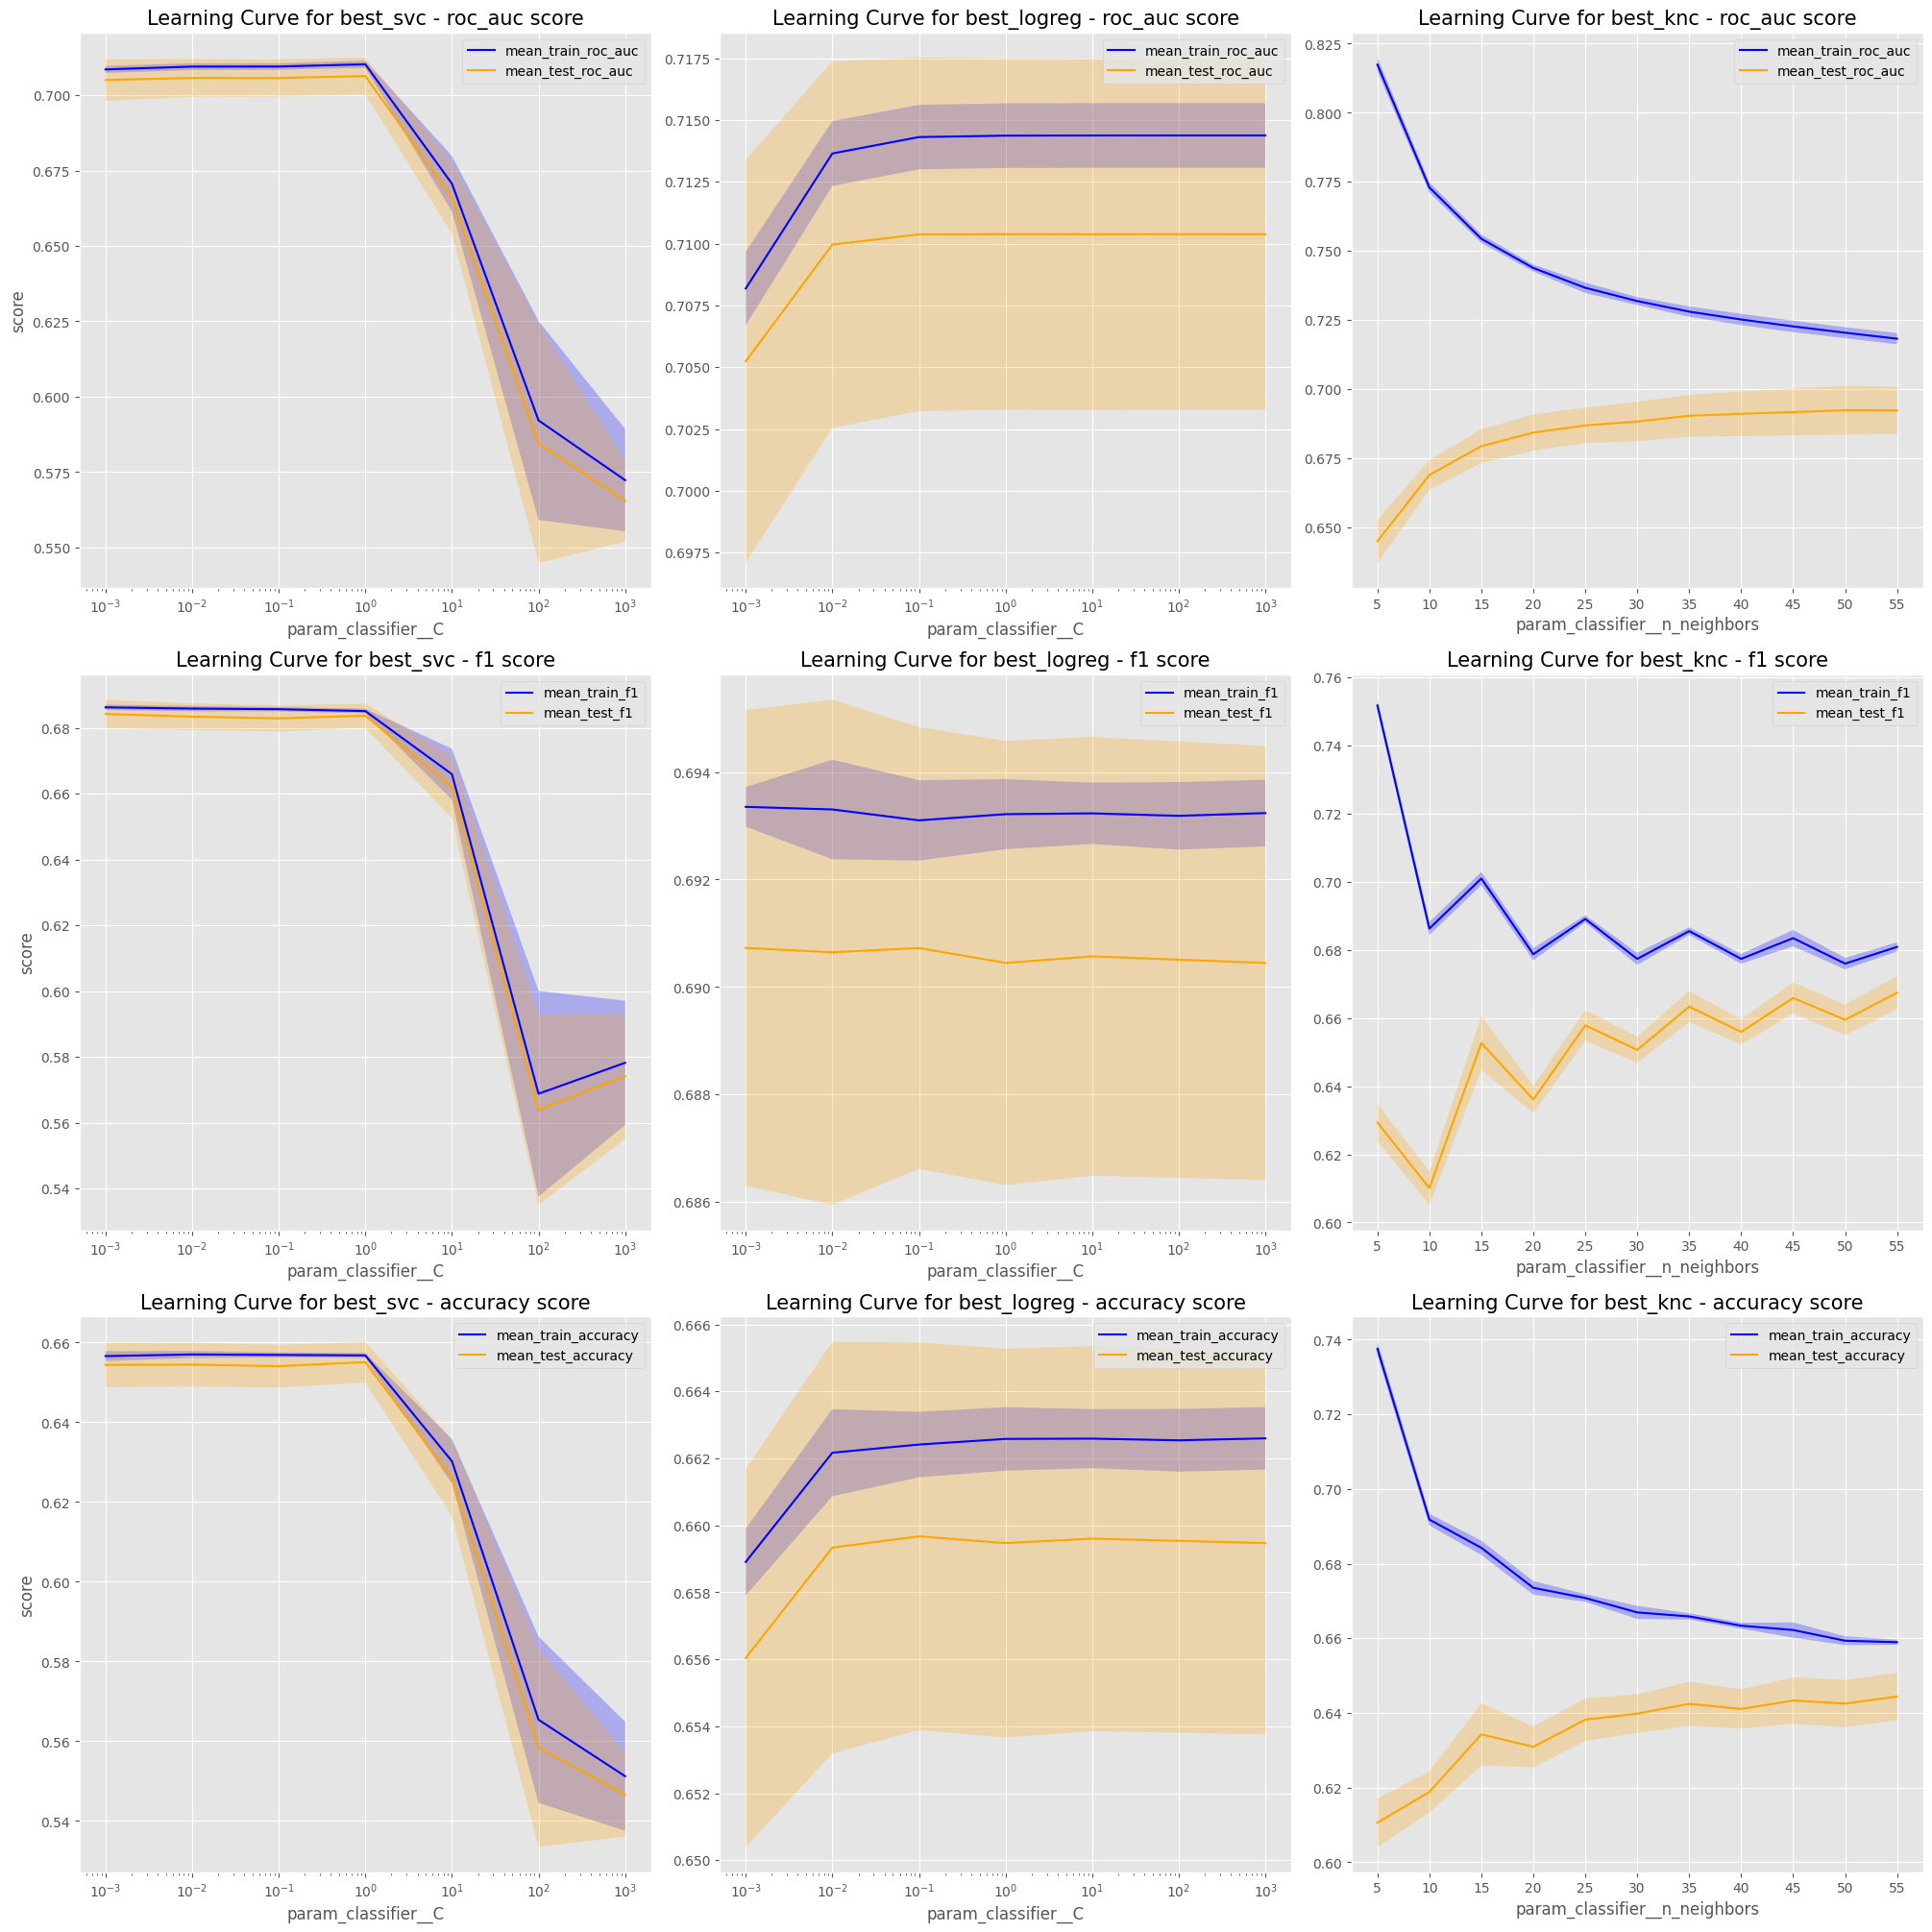

In [163]:
# Create list of grids and list of names
grids = [best_svc, best_logreg, best_knc]
names = ['best_svc', 'best_logreg', 'best_knc']
metrics = ['roc_auc', 'f1', 'accuracy']

# Plot learning curves
plt.style.use('ggplot')
fig, axes = plt.subplots(3, 3, figsize=(20,20), constrained_layout=True,)
for i in range(3):
    axes[i, 0].set_ylabel('score', fontsize=12)
    for j in range(3):
        # Define ax
        ax = axes[j, i]
        
        # Get parameter name and list of parameter values
        param_name = list(grids[i].best_params_.keys())[0]
        param_values = [k[param_name] for k in grids[i].cv_results_['params']]

        # Get mean and sd train and test scores
        mean_train_score = grids[i].cv_results_[f'mean_train_{metrics[j]}']
        std_train_score = grids[i].cv_results_[f'std_train_{metrics[j]}']

        mean_test_score = grids[i].cv_results_[f'mean_test_{metrics[j]}']
        std_test_score = grids[i].cv_results_[f'std_test_{metrics[j]}']


        # Plot mean train and test score for each parameter value
        ax.plot(param_values, mean_train_score, label=f'mean_train_{metrics[j]}', color='blue')
        ax.plot(param_values, mean_test_score, label=f'mean_test_{metrics[j]}', color='orange')

        # Plot mean +- sd interval for train data
        ax.fill_between(x=param_values,
                        y1=mean_train_score+std_train_score,
                        y2=mean_train_score-std_train_score,
                        alpha=0.25, facecolor='blue')

        # Plot mean +- sd interval for test data
        ax.fill_between(x=param_values,
                        y1=mean_test_score+std_test_score,
                        y2=mean_test_score-std_test_score,
                        alpha=0.25, facecolor='orange')
        # Set ticks
        ax.set_xticks(param_values)

        # Label graph
        ax.set_xlabel(f'param_{param_name}', fontsize=12)
        ax.set_title(f'Learning Curve for {names[i]} - {metrics[j]} score', fontsize=15)
        ax.legend()
        if i < 2:
            ax.set_xscale('log')

In [164]:
# Get best parameters for all models
print(f'best_svc : {best_svc.best_params_}')
print(f'best_logreg : {best_logreg.best_params_}')
print(f'best_knc : {best_knc.best_params_}')

best_svc : {'classifier__C': 1.0}
best_logreg : {'classifier__C': 1.0}
best_knc : {'classifier__n_neighbors': 50}


In [ ]:
# Get necessary lists
best_models = [best_svc.best_estimator_, best_logreg.best_estimator_, best_knc.best_estimator_]
index_best_models = ['best_svc', 'best_logreg', 'best_knc']

# Make summary for best models (about 30 seconds)
summary_best_models = make_summary(models=best_models, index=index_best_models)

In [166]:
# View summary
summary_best_models

,Train Accuracy,Test Accuracy,Mean CV Accuracy,Precision,Recall,F1,Mean CV AUC,Test AUC
best_svc,0.66,0.65,0.66,0.66,0.69,0.68,0.71,0.65
best_logreg,0.66,0.65,0.66,0.66,0.70,0.68,0.71,0.65
best_knc,0.66,0.63,0.64,0.66,0.64,0.65,0.69,0.63


## Finding the best RandomForest model

In [167]:
# Define lists to hold train and test scores
warm_start_train_auc = []
warm_start_test_auc = []

warm_start_train_accuracy = []
warm_start_test_accuracy = []

# Define model
warm_start_rf = RandomForestClassifier(warm_start=True, random_state=0)

# Use warm start to find the optimal n_estimators value
for n_estimators in range(1, 100, 5):
    # Assign n_estimators to the model
    warm_start_rf.n_estimators = n_estimators

    # Fit model
    warm_start_rf.fit(X=X_train, y=y_train)

    # Get predictions
    train_preds = warm_start_rf.predict(X=X_train)
    test_preds = warm_start_rf.predict(X=X_test)

    # Append train and test scores to the corresponding lists
    warm_start_train_auc.append(roc_auc_score(y_true=y_train, y_score=train_preds))
    warm_start_test_auc.append(roc_auc_score(y_true=y_test, y_score=test_preds))

    warm_start_train_accuracy.append(warm_start_rf.score(X=X_train, y=y_train))
    warm_start_test_accuracy.append(warm_start_rf.score(X=X_test, y=y_test))

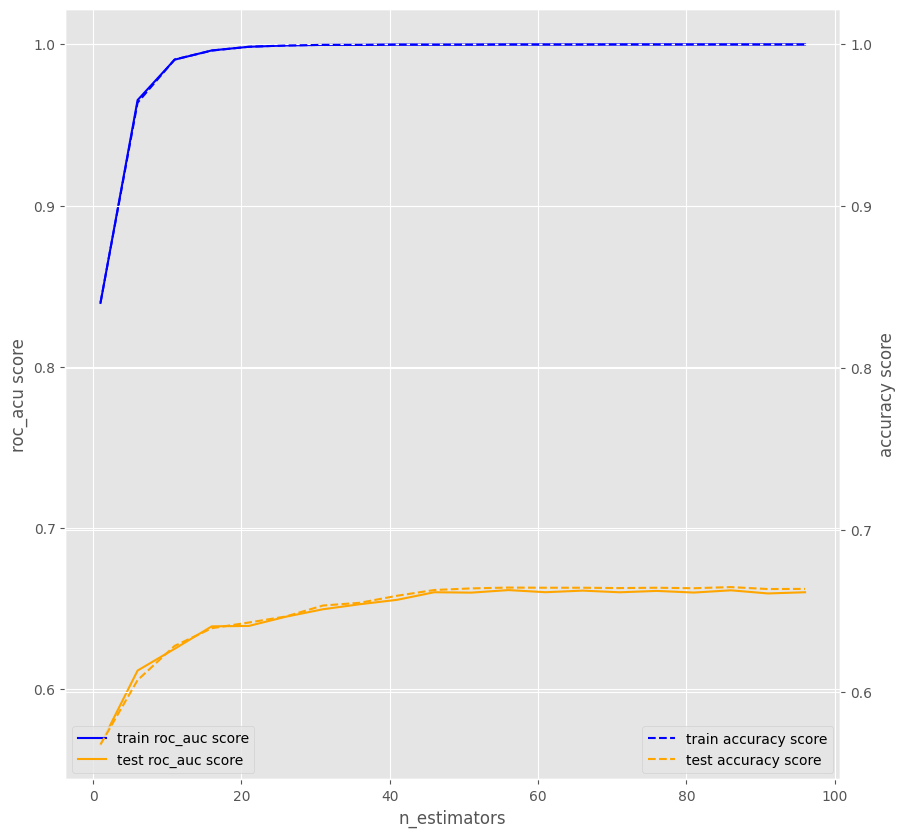

In [168]:
# Plot results
fig, ax1 = plt.subplots(1, 1, figsize=(10, 10))
xs = range(1, 100, 5)
ax1.plot(xs, warm_start_train_auc, color='blue', label='train roc_auc score')
ax1.plot(xs, warm_start_test_auc, color='orange', label='test roc_auc score')

# Add axes labels and legend
ax1.set_xlabel('n_estimators', fontsize=12)
ax1.set_ylabel('roc_acu score', fontsize=12)
ax1.legend(loc=3)

# Create second axis
ax2 = ax1.twinx()

ax2.plot(xs, warm_start_train_accuracy, color='blue', label='train accuracy score', linestyle='dashed')
ax2.plot(xs, warm_start_test_accuracy, color='orange', label='test accuracy score', linestyle='dashed')

# Add axes labels and legend
ax2.set_ylabel('accuracy score', fontsize=12)
ax2.legend(loc=0)

In [169]:
# Define random forest model
untuned_rfc = RandomForestClassifier(random_state=0, n_jobs=-1)

# Define parameter grid for random forest
param_grid_rfc = {
    'max_features' : ['sqrt', 1, 5, 10, 15, 25, 35, 45],
    'min_samples_split' : [2, 10, 25, 50, 75, 100],
    'max_depth' : [None, 4, 8, 12, 16, 20, 24],
}

tuned_rfc = GridSearchCV(estimator=RandomForestClassifier(n_estimators=60, random_state=0),
                         param_grid=param_grid_rfc,
                         cv=5,
                         scoring=('roc_auc', 'f1', 'accuracy'),
                         refit='roc_auc',
                         return_train_score=True,
                         verbose=10,
                         n_jobs=8)

In [170]:
# Fit rfcs
untuned_rfc.fit(X=X_train, y=y_train)
# tuned_rfc.fit(X=X_train, y=y_train)

RandomForestClassifier(n_jobs=-1, random_state=0)

In [171]:
# Load the fitted model to save about 2 hours
tuned_rfc = load('tuned_rfc.joblib')

In [172]:
# Define best_rfc
best_rfc = tuned_rfc.best_estimator_

In [173]:
# Get parameters of the best model
tuned_rfc.best_params_

{'max_depth': 24, 'max_features': 'sqrt', 'min_samples_split': 100}

In [174]:
# Create summary dataframe (about 40 seconds)
summary_rfc = make_summary(models=[best_rfc], index=['best_rfc'])

# View summary
summary_rfc

,Train Accuracy,Test Accuracy,Mean CV Accuracy,Precision,Recall,F1,Mean CV AUC,Test AUC
best_rfc,0.76,0.66,0.67,0.66,0.74,0.7,0.73,0.66


In [175]:
# Make and view overall summary
summary_overall = pd.concat([summary_rfc, summary_best_models])
summary_overall

,Train Accuracy,Test Accuracy,Mean CV Accuracy,Precision,Recall,F1,Mean CV AUC,Test AUC
best_rfc,0.76,0.66,0.67,0.66,0.74,0.70,0.73,0.66
best_svc,0.66,0.65,0.66,0.66,0.69,0.68,0.71,0.65
best_logreg,0.66,0.65,0.66,0.66,0.70,0.68,0.71,0.65
best_knc,0.66,0.63,0.64,0.66,0.64,0.65,0.69,0.63


Text(0.5, 0.98, 'ROC Curves for all best models')

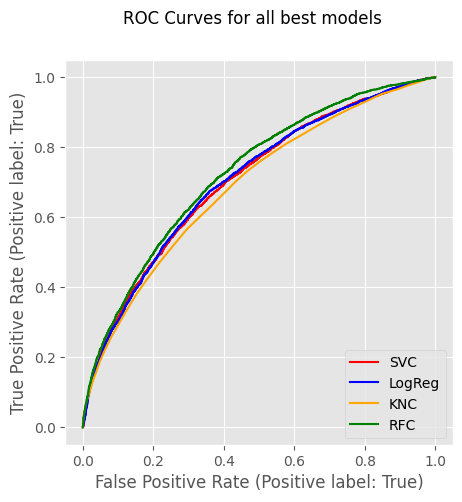

In [176]:
# Plot roc curves for all models
fig, ax = plt.subplots(1, 1, figsize=(5,5))
svc_disp = RocCurveDisplay.from_estimator(estimator=best_svc, X=X_test, y=y_test, color='red', ax=ax, label='SVC')
logreg_disp = RocCurveDisplay.from_estimator(estimator=best_logreg, X=X_test, y=y_test, color='blue', ax=ax, label='LogReg')
knc_disp = RocCurveDisplay.from_estimator(estimator=best_knc, X=X_test, y=y_test, color='orange', ax=ax, label='KNC')
rfc_disp = RocCurveDisplay.from_estimator(estimator=best_rfc, X=X_test, y=y_test, color='green', ax=ax, label='RFC')
fig.suptitle('ROC Curves for all best models')

## In-depth analysis using the best model

### Feature Selection

In [177]:
# Get feature importances
fi = best_rfc.feature_importances_

# Get f and p values
f_statistic, p_values = f_classif(X=X_train, y=y_train)

In [ ]:
# Initiate a recursive feature elimination procedure to get the feature rankings (about 15 minutes)
rfe = RFE(estimator=best_rfc, n_features_to_select=1, verbose=10)
rfe.fit(X=X_train, y=y_train)

In [178]:
# Save ranking from rfe.ranking_ to save time fitting multiple times
ranking = np.array([ 4, 40, 19, 11, 59, 7, 25, 42, 31, 51, 23, 50, 57, 17, 52, 32, 33,
                     30, 47, 27, 14, 34, 39, 15, 12, 2,  1,  8, 21,  3, 56, 55, 53, 58,
                     54, 38, 48, 13, 6, 10,  9, 22, 5, 16, 18, 20, 28, 35, 26, 24, 37,
                     49, 29, 46, 43, 41, 36, 44, 45])

Text(0.5, 0.9, 'Feature Importances and F-Statistics scaled by RFE ranking')

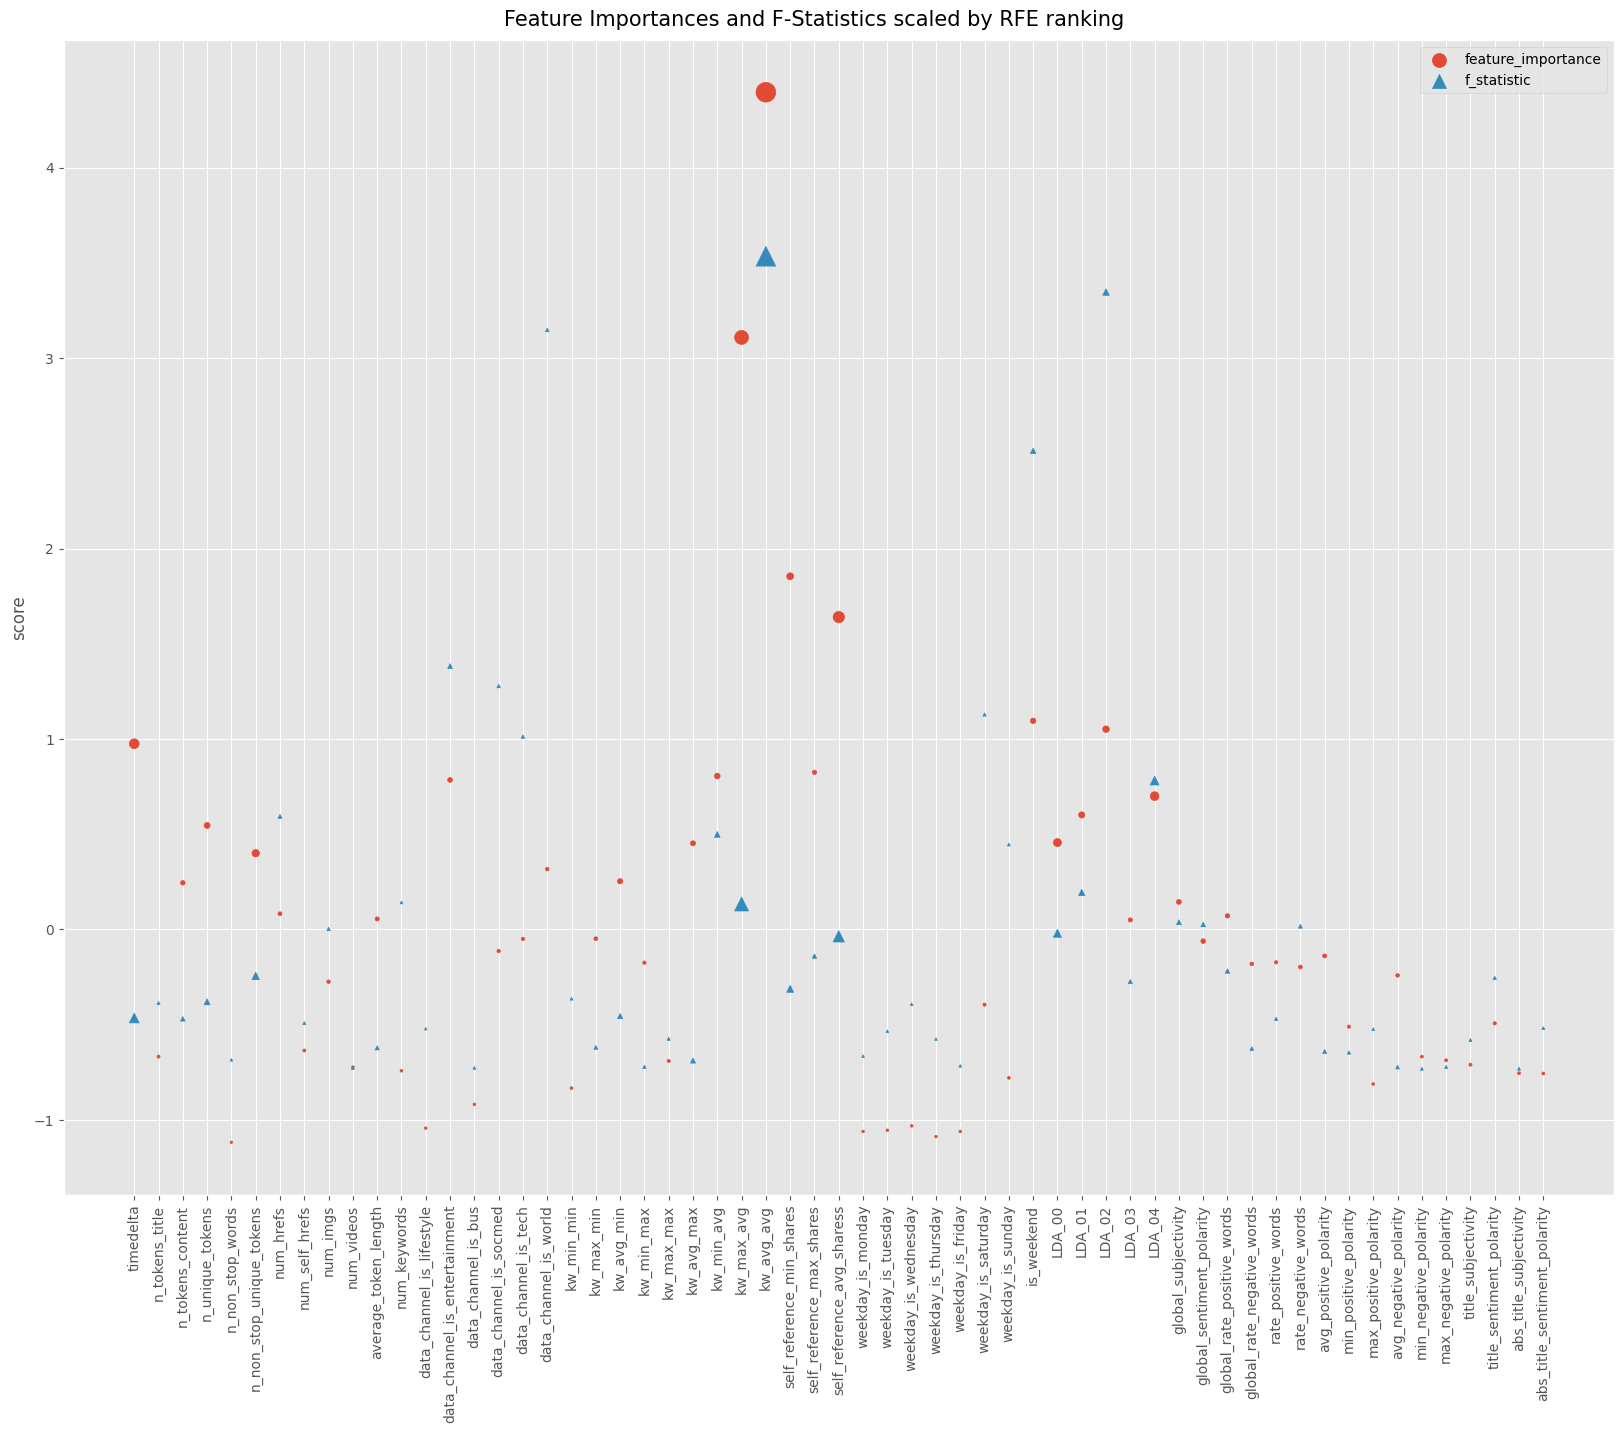

In [179]:
# Plot the f-scores and feature importances
plt.style.use('ggplot')
fig, ax = plt.subplots(1, 1, figsize=(20, 15))
n = len(best_rfc.feature_names_in_)

# Plot feature importances standardised and have markers scaled by feature ranking
ax.scatter(range(n), 
           StandardScaler().fit_transform(fi.reshape(-1,1)).reshape(59,),
           marker='o',
           s=200/ranking,
           label='feature_importance')

# Plot f-scpres standardised and have markers scaled by feature ranking
ax.scatter(range(n), 
           StandardScaler().fit_transform(f_statistic.reshape(-1,1)).reshape(59,),
           marker='^',
           s=200/ranking,
           label='f_statistic')

# Set labels and add legend
ax.set_xticks(ticks=range(n), labels=best_rfc.feature_names_in_, rotation=90);
ax.set_ylabel('score')
ax.legend()
fig.suptitle('Feature Importances and F-Statistics scaled by RFE ranking', y=0.90, fontsize=15)

In [180]:
# Define list to store the pruned models and summaries of each model
summaries_pruned = []
pruned_fitted_models_cms = []

# Iterate over different choices for n_features to be used (about 4 minutes)
for n_features in tqdm([5, 10, 15, 20, 25, 30]):
    # Define new train and test data
    X_train_new = X_train.drop([X_train.columns[i] for i in range(59) if ranking[i] > n_features], axis='columns')
    X_test_new = X_test.drop([X_test.columns[i] for i in range(59) if ranking[i] > n_features], axis='columns')

    # Define and fit current model
    current_rfc = clone(estimator=best_rfc)
    current_rfc.fit(X=X_train_new, y=y_train)

    # Get predictions and confusion matrix
    preds = current_rfc.predict(X=X_test_new)
    cm = confusion_matrix(y_true=y_test, y_pred=preds)

    # Make summary for current model
    summary = make_summary(models=[current_rfc],
                           X_train=X_train_new,
                           X_test=X_test_new,
                           index=[f'n_features : {n_features}'])
    
    # Append current model and summary to lists
    pruned_fitted_models_cms.append(cm)
    summaries_pruned.append(summary)

100%|██████████| 6/6 [04:15<00:00, 42.61s/it]


In [181]:
# Concatenate all pruned summaries and rfc summary 
pd.concat(summaries_pruned + [summary_rfc])

,Train Accuracy,Test Accuracy,Mean CV Accuracy,Precision,Recall,F1,Mean CV AUC,Test AUC
n_features : 5,0.71,0.63,0.64,0.63,0.74,0.68,0.68,0.63
n_features : 10,0.74,0.65,0.65,0.65,0.73,0.69,0.70,0.64
n_features : 15,0.75,0.66,0.66,0.66,0.74,0.70,0.72,0.66
n_features : 20,0.75,0.66,0.67,0.66,0.74,0.70,0.72,0.66
n_features : 25,0.76,0.66,0.67,0.66,0.74,0.70,0.72,0.66
n_features : 30,0.76,0.66,0.67,0.66,0.74,0.70,0.72,0.66
best_rfc,0.76,0.66,0.67,0.66,0.74,0.70,0.73,0.66


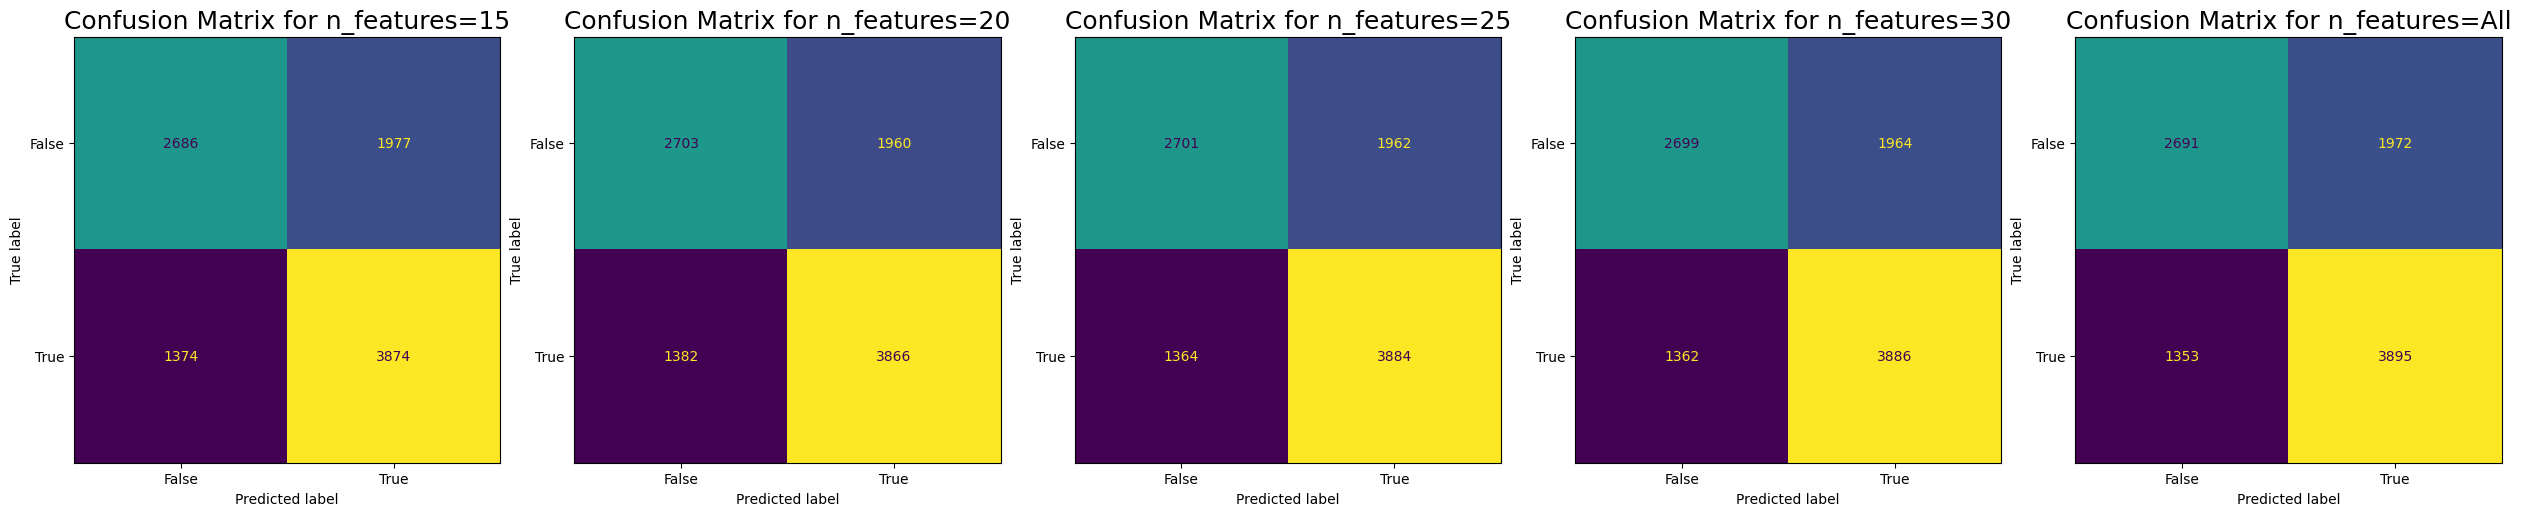

In [182]:
# Get confusion matrix for best_rfc
cm_best_rfc = confusion_matrix(y_true=y_test, 
                               y_pred=best_rfc.predict(X=X_test))

# Plot confusion matrices for candidate models
plt.style.use('default')
fig, axes = plt.subplots(1, 5, figsize=(25, 10), constrained_layout=True)

# Iterate through and plot all confusion matrices
for cm, n_features, ax in zip(pruned_fitted_models_cms[2:] + [cm_best_rfc], [15, 20, 25, 30, 'All'] , axes.ravel()):
    # Plot the confusion matrix
    ConfusionMatrixDisplay(cm, display_labels=[False, True]).plot(ax=ax, colorbar=False)

    # Add titl
    ax.set_title(f'Confusion Matrix for n_features={n_features}', fontsize=18)

In [183]:
# Define list to store the pruned models and summaries of each model
summaries_pruned = []
pruned_fitted_models_cms = []

# Iterate over different choices for n_features to be used (about 4.5 minutes)
for n_features in tqdm([10, 11, 12, 13, 14, 15]):
    # Define new train and test data
    X_train_new = X_train.drop([X_train.columns[i] for i in range(59) if ranking[i] > n_features], axis='columns')
    X_test_new = X_test.drop([X_test.columns[i] for i in range(59) if ranking[i] > n_features], axis='columns')

    # Define and fit current model
    current_rfc = clone(estimator=best_rfc)
    current_rfc.fit(X=X_train_new, y=y_train)

    # Get predictions and confusion matrix
    preds = current_rfc.predict(X=X_test_new)
    cm = confusion_matrix(y_true=y_test, y_pred=preds)

    # Make summary for current model
    summary = make_summary(models=[current_rfc],
                           X_train=X_train_new,
                           X_test=X_test_new,
                           index=[f'n_features : {n_features}'])
    
    # Append current model and summary to lists
    pruned_fitted_models_cms.append(cm)
    summaries_pruned.append(summary)

100%|██████████| 6/6 [04:34<00:00, 45.69s/it]


In [184]:
# Concatenate all pruned summaries and rfc summary 
pd.concat(summaries_pruned + [summary_rfc])

,Train Accuracy,Test Accuracy,Mean CV Accuracy,Precision,Recall,F1,Mean CV AUC,Test AUC
n_features : 10,0.74,0.65,0.65,0.65,0.73,0.69,0.70,0.64
n_features : 11,0.74,0.65,0.65,0.65,0.73,0.69,0.71,0.64
n_features : 12,0.74,0.65,0.65,0.65,0.74,0.69,0.71,0.65
n_features : 13,0.75,0.66,0.66,0.66,0.74,0.70,0.72,0.66
n_features : 14,0.75,0.66,0.66,0.66,0.74,0.70,0.72,0.65
n_features : 15,0.75,0.66,0.66,0.66,0.74,0.70,0.72,0.66
best_rfc,0.76,0.66,0.67,0.66,0.74,0.70,0.73,0.66


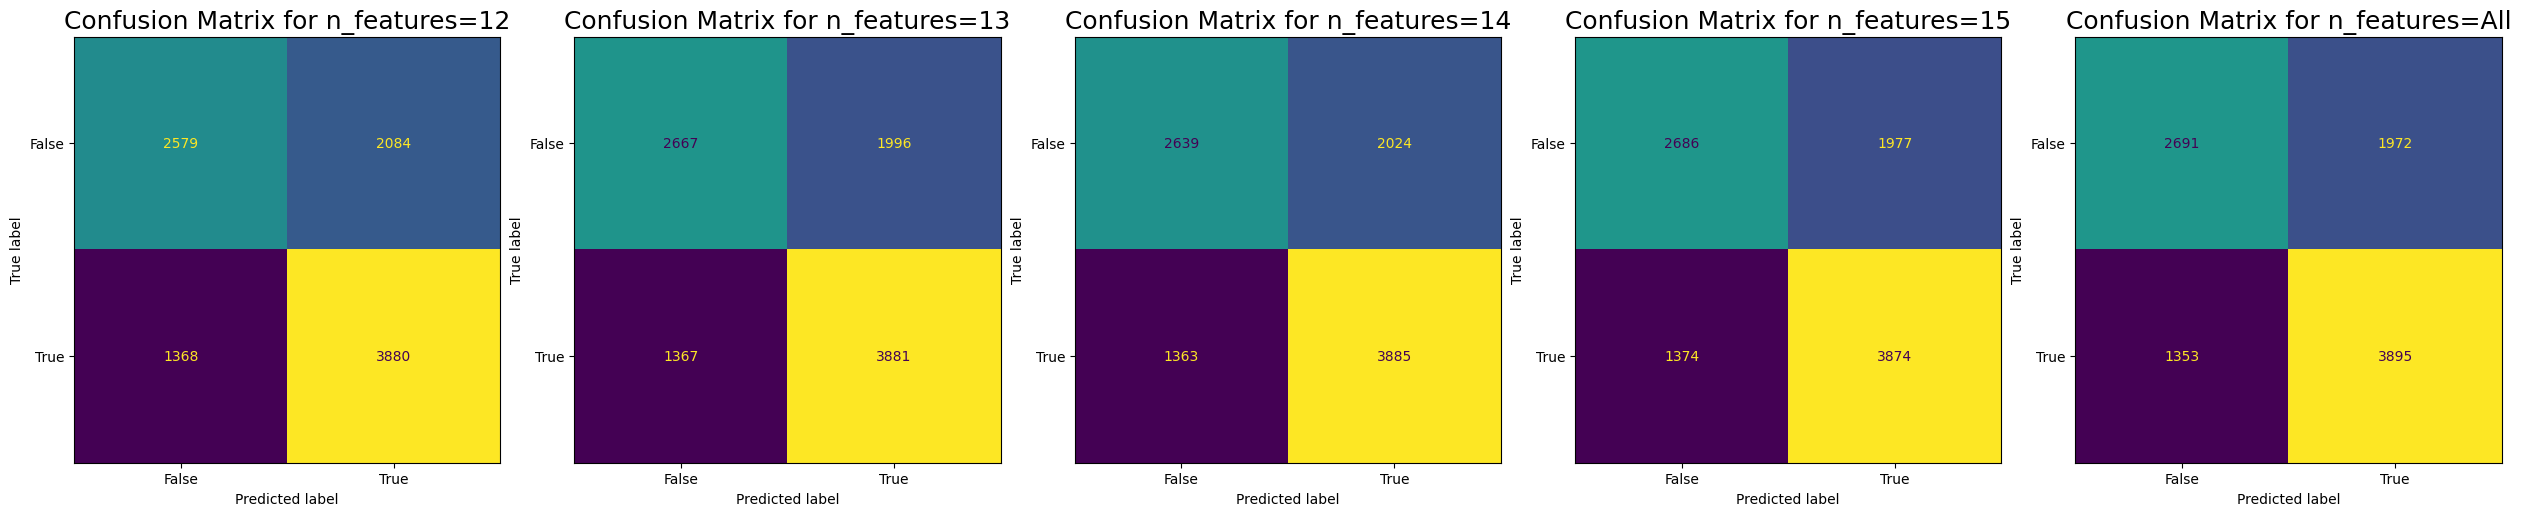

In [185]:
# Get confusion matrix for best_rfc
cm_best_rfc = confusion_matrix(y_true=y_test, 
                               y_pred=best_rfc.predict(X=X_test))

# Plot confusion matrices for candidate models
plt.style.use('default')
fig, axes = plt.subplots(1, 5, figsize=(25, 10), constrained_layout=True)

# Iterate through and plot all confusion matrices
for cm, n_features, ax in zip(pruned_fitted_models_cms[2:] + [cm_best_rfc], [12, 13, 14, 15, 'All'] , axes.ravel()):
    # Plot the confusion matrix
    ConfusionMatrixDisplay(cm, display_labels=[False, True]).plot(ax=ax, colorbar=False)

    # Add titl
    ax.set_title(f'Confusion Matrix for n_features={n_features}', fontsize=18)

### Define pruned model

In [186]:
# Define new pruned dataset
X_pruned = X.drop([X.columns[i] for i in range(59) if ranking[i] > 13], axis='columns')

In [187]:
# Define new model for pruned data
pruned_rfc = clone(estimator=best_rfc)

In [188]:
summary_pruned_rfc = summaries_pruned[3]
summary_pruned_rfc.index = ['pruned_rfc']

### Different train and test sizes

In [189]:
# Create test size and stratified and non stratified score lists
cv_scores = []
test_scores = []
test_size_cms = []

# Iterate through different test sizes and calculate scores (about 3.5 minutes)
for size in tqdm(np.arange(0.05, 0.65, 0.05)):   
    # Split the data without and with stratifying
    X_train, X_test, y_train, y_test = train_test_split(X_pruned, y, test_size=size, random_state=0)

    # Fit model on new split
    pruned_rfc.fit(X=X_train, y=y_train) 

    # Get predictions and confusion matrix
    preds = pruned_rfc.predict(X=X_test)
    cm = confusion_matrix(y_true=y_test, y_pred=preds)
    
    # Get scores and append to corresponding lists
    cv_scores.append(cross_val_score(estimator=pruned_rfc,
                                     X=X_train, y=y_train,
                                     cv=5,
                                     n_jobs=-1,
                                     scoring='roc_auc').mean())
    
    test_scores.append(roc_auc_score(y_true=y_test, y_score=preds))
    
    # Append cm to list
    test_size_cms.append(cm)


100%|██████████| 12/12 [03:36<00:00, 18.06s/it]


Text(0.5, 0.98, 'Mean CV and Test AUC score for different test sizes')

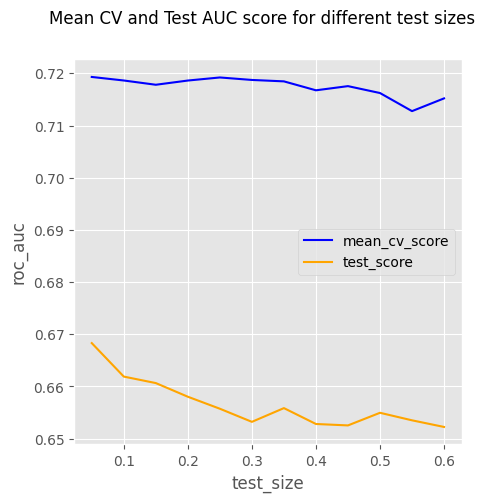

In [190]:
# Plot scores for each train size
plt.style.use('ggplot')
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.plot(np.arange(0.05, 0.65, 0.05), cv_scores, label='mean_cv_score', color='blue')
ax.plot(np.arange(0.05, 0.65, 0.05), test_scores, label='test_score', color='orange')

# Change axis labels and add legend
ax.set_xlabel('test_size')
ax.set_ylabel('roc_auc')
ax.legend()
fig.suptitle('Mean CV and Test AUC score for different test sizes')

In [191]:
# Split data
X_train_pruned, X_test_pruned, y_train_pruned, y_test_pruned = train_test_split(X_pruned, y, test_size=0.30, random_state=0)

# Get scaled versions of train and test data
scaler = StandardScaler()
X_train_pruned_scaled = scaler.fit_transform(X=X_train_pruned)
X_test_pruned_scaled = scaler.transform(X=X_test_pruned)

# Convert scaled versions to dataframes
X_train_pruned_scaled = pd.DataFrame(data=X_train_pruned_scaled,
                                     index=X_train_pruned.index,
                                     columns=X_pruned.columns)

X_test_pruned_scaled = pd.DataFrame(data=X_test_pruned_scaled,
                                    index=X_test_pruned.index,
                                    columns=X_pruned.columns)

In [192]:
# Fit model on train data
pruned_rfc.fit(X=X_train_pruned, y=y_train_pruned)

RandomForestClassifier(max_depth=24, min_samples_split=100, n_estimators=60,
                       random_state=0)

### Outlier Detection with Isolation Forest

**Add outlier column**

In [202]:
# Define and fit isolation forest
iso = IsolationForest().fit(X=X_train_pruned)

# Predict which samples of the dataset will be outliers
iso_train_outliers = iso.predict(X=X_train_pruned)
iso_test_outliers = iso.predict(X=X_test_pruned)

In [203]:
# Add a new column to identify outliers 
X_train_outliers = X_train_pruned.copy()
X_train_outliers['outlier'] = iso_train_outliers == -1

# Add a new column to identify outliers 
X_test_outliers = X_test_pruned.copy()
X_test_outliers['outlier'] = iso_test_outliers == -1

In [204]:
# Define and fit new model on outlier indicating data
outlier_rfc = clone(estimator=pruned_rfc)
outlier_rfc.fit(X=X_train_outliers, y=y_train_pruned)

RandomForestClassifier(max_depth=24, min_samples_split=100, n_estimators=60,
                       random_state=0)

In [205]:
# Make summary
summary_outlier_iso = make_summary(models=[outlier_rfc],
                                   X_train=X_train_outliers,
                                   X_test=X_test_outliers,
                                   y_train=y_train_pruned,
                                   y_test=y_test_pruned,
                                   index=['outlier_rfc_iso'])

# View summary
pd.concat([summary_outlier_iso, summary_pruned_rfc])

,Train Accuracy,Test Accuracy,Mean CV Accuracy,Precision,Recall,F1,Mean CV AUC,Test AUC
outlier_rfc_iso,0.74,0.66,0.66,0.66,0.74,0.7,0.72,0.65
pruned_rfc,0.75,0.66,0.66,0.66,0.74,0.7,0.72,0.66


**Drop Outliers**

In [206]:
# Get indexes of outliers
train_outliers_indx = X_train_outliers[X_train_outliers['outlier'] == True].index
test_outliers_indx = X_test_outliers[X_test_outliers['outlier'] == True].index

# Drop outliers
X_train_drop_outliers = X_train_outliers.drop(train_outliers_indx, axis=0)
y_train_drop_outliers = y_train_pruned.drop(train_outliers_indx)

X_test_drop_outliers = X_test_outliers.drop(test_outliers_indx, axis=0)
y_test_drop_outliers = y_test_pruned.drop(test_outliers_indx)

In [207]:
# Define and fit new model on dataset without outliers
no_outlier_rfc = clone(estimator=pruned_rfc)
no_outlier_rfc.fit(X=X_train_drop_outliers, y=y_train_drop_outliers)

RandomForestClassifier(max_depth=24, min_samples_split=100, n_estimators=60,
                       random_state=0)

In [208]:
# Make summary
summary_no_outliers_iso = make_summary(models=[no_outlier_rfc],
                                       X_train=X_train_drop_outliers,
                                       X_test=X_test_drop_outliers,
                                       y_train=y_train_drop_outliers,
                                       y_test=y_test_drop_outliers,
                                       index=['no_outlier_rfc_iso'])

In [209]:
# View summary
pd.concat([summary_no_outliers_iso, summary_pruned_rfc])

,Train Accuracy,Test Accuracy,Mean CV Accuracy,Precision,Recall,F1,Mean CV AUC,Test AUC
no_outlier_rfc_iso,0.74,0.65,0.66,0.65,0.71,0.68,0.71,0.65
pruned_rfc,0.75,0.66,0.66,0.66,0.74,0.70,0.72,0.66


### Outlier Detection with PCA and EllipticEnvelope

**Add outlier column**

In [210]:
# Define pca
pca = PCA(n_components=0.8)

# Fit pca and transform the train and test datasets
X_train_pca = pca.fit_transform(X=X_train_pruned_scaled)
X_test_pca = pca.transform(X=X_test_pruned_scaled)

In [211]:
# Define elliptic envelope
ee = EllipticEnvelope().fit(X=X_train_pca)

# Predict which samples of the dataset will be outliers
ee_train_outliers = ee.predict(X=X_train_pca)
ee_test_outliers = ee.predict(X=X_test_pca)

In [212]:
# Add a new column to identify outliers 
X_train_outliers = X_train_pruned.copy()
X_train_outliers['outlier'] = ee_train_outliers == -1

# Add a new column to identify outliers 
X_test_outliers = X_test_pruned.copy()
X_test_outliers['outlier'] = ee_test_outliers == -1

In [213]:
# Define and fit new model on outlier indicating data
ee_outlier_rfc = clone(estimator=pruned_rfc)
ee_outlier_rfc.fit(X=X_train_outliers, y=y_train_pruned)

RandomForestClassifier(max_depth=24, min_samples_split=100, n_estimators=60,
                       random_state=0)

In [214]:
# Make summary
summary_outlier_ee = make_summary(models=[ee_outlier_rfc],
                                  X_train=X_train_outliers,
                                  X_test=X_test_outliers,
                                  y_train=y_train_pruned,
                                  y_test=y_test_pruned,
                                  index=['outlier_rfc_ee'])

In [215]:
# View summary
pd.concat([summary_outlier_ee, summary_pruned_rfc])

,Train Accuracy,Test Accuracy,Mean CV Accuracy,Precision,Recall,F1,Mean CV AUC,Test AUC
outlier_rfc_ee,0.74,0.66,0.66,0.66,0.74,0.7,0.72,0.65
pruned_rfc,0.75,0.66,0.66,0.66,0.74,0.7,0.72,0.66


**Drop Outliers**

In [216]:
# Get indexes of outliers
train_outliers_indx = X_train_outliers[X_train_outliers['outlier'] == True].index
test_outliers_indx = X_test_outliers[X_test_outliers['outlier'] == True].index

# Drop outliers
X_train_drop_outliers = X_train_outliers.drop(train_outliers_indx, axis=0)
y_train_drop_outliers = y_train_pruned.drop(train_outliers_indx)

X_test_drop_outliers = X_test_outliers.drop(test_outliers_indx, axis=0)
y_test_drop_outliers = y_test_pruned.drop(test_outliers_indx)

In [217]:
# Define and fit new model on dataset without outliers
no_outlier_rfc = clone(estimator=pruned_rfc)
no_outlier_rfc.fit(X=X_train_drop_outliers, y=y_train_drop_outliers)

RandomForestClassifier(max_depth=24, min_samples_split=100, n_estimators=60,
                       random_state=0)

In [218]:
# Make summary
summary_no_outliers_ee = make_summary(models=[no_outlier_rfc],
                                   X_train=X_train_drop_outliers,
                                   X_test=X_test_drop_outliers,
                                   y_train=y_train_drop_outliers,
                                   y_test=y_test_drop_outliers,
                                   index=['no_outlier_rfc_ee'])
# View summary
pd.concat([summary_no_outliers_ee, summary_pruned_rfc])

,Train Accuracy,Test Accuracy,Mean CV Accuracy,Precision,Recall,F1,Mean CV AUC,Test AUC
no_outlier_rfc_ee,0.74,0.65,0.65,0.64,0.70,0.67,0.71,0.65
pruned_rfc,0.75,0.66,0.66,0.66,0.74,0.70,0.72,0.66


In [219]:
pd.concat([summary_outlier_iso, summary_no_outliers_iso, summary_outlier_ee, summary_no_outliers_ee, summary_pruned_rfc])

,Train Accuracy,Test Accuracy,Mean CV Accuracy,Precision,Recall,F1,Mean CV AUC,Test AUC
outlier_rfc_iso,0.74,0.66,0.66,0.66,0.74,0.70,0.72,0.65
no_outlier_rfc_iso,0.74,0.65,0.66,0.65,0.71,0.68,0.71,0.65
outlier_rfc_ee,0.74,0.66,0.66,0.66,0.74,0.70,0.72,0.65
no_outlier_rfc_ee,0.74,0.65,0.65,0.64,0.70,0.67,0.71,0.65
pruned_rfc,0.75,0.66,0.66,0.66,0.74,0.70,0.72,0.66


### Outlier Detection with Clustering

**Add outlier column**

In [220]:
# Get the indices of the samples defined as outliers by clustering 
cluster_outlier_indx = [3168, 3562, 3648, 3783, 3878, 4438, 5413, 5417, 5504, 5554, 5598, 5660, 5674, 5736, 5870, 6131, 6345,
                        6383, 6597, 6598, 6651, 6944, 7109, 7692, 7885, 8559, 9268, 9328, 9379, 10261, 10297, 10336, 10388,
                        10619, 11319, 11344, 11843, 12300, 13366, 14218, 14684, 14926, 15198, 15205, 15752, 16268, 16281, 16294,
                        16334, 16348, 16384, 16430, 16465, 16467, 16482, 16553, 16801, 17137, 17282, 17300, 17319, 17388, 17426,
                        17461, 17500, 17784, 17837, 17863, 18037, 18101, 18188, 18303, 19064, 19241, 19304, 19357, 19714, 19850,
                        20919, 21120, 21153, 21592, 21669, 22077, 22148, 22687, 22859, 23062, 23166, 23226, 23238, 23239, 23240,
                        23309, 23310, 23344, 23357, 23362, 23372, 23379, 23385, 23404, 23447, 23479, 23480, 23481, 23595, 23622,
                        23684, 23714, 23799, 23857, 23862, 23974, 24075, 24344, 24418, 24460, 24555, 24792, 24918, 25420, 25559,
                        25842, 25915, 26096, 26259, 26335, 26477, 26607, 26610, 26668, 26759, 26837, 26839, 26910, 26926, 27575,
                        27678, 27756, 27827, 28027, 28124, 28163, 28529, 28702, 28927, 29102, 29269, 30415, 30520, 30977, 31497,
                        32070, 33406, 33572, 34699, 35246, 35397, 36113, 37005, 37427, 37442]

train_outliers_indx = list(set(X_train_pruned.index).intersection(set(cluster_outlier_indx)))
test_outliers_indx = list(set(X_test_pruned.index).intersection(set(cluster_outlier_indx)))

In [ ]:
# Add a new column to identify outliers 
X_train_outliers = X_train_pruned.copy()
X_train_outliers['outlier'] = False
X_train_outliers['outlier'].loc[train_outliers_indx] = True

# Add a new column to identify outliers 
X_test_outliers = X_test_pruned.copy()
X_test_outliers['outlier'] = False
X_test_outliers['outlier'].loc[test_outliers_indx] = True

In [222]:
# Define and fit new model
cluster_outlier_rfc = clone(estimator=pruned_rfc)
cluster_outlier_rfc.fit(X=X_train_outliers, y=y_train_pruned)

# Make summary
summary_outlier_cluster = make_summary(models=[cluster_outlier_rfc],
                                       X_train=X_train_outliers,
                                       X_test=X_test_outliers,
                                       y_train=y_train_pruned,
                                       y_test=y_test_pruned,
                                       index=['outlier_rfc_cluster'])

# View summary
pd.concat([summary_outlier_cluster, summary_pruned_rfc])

,Train Accuracy,Test Accuracy,Mean CV Accuracy,Precision,Recall,F1,Mean CV AUC,Test AUC
outlier_rfc_cluster,0.74,0.66,0.66,0.66,0.74,0.7,0.72,0.66
pruned_rfc,0.75,0.66,0.66,0.66,0.74,0.7,0.72,0.66


**Drop Outliers**

In [223]:
# Drop outliers
X_train_drop_outliers = X_train_outliers.drop(train_outliers_indx, axis=0)
y_train_drop_outliers = y_train_pruned.drop(train_outliers_indx)

X_test_drop_outliers = X_test_outliers.drop(test_outliers_indx, axis=0)
y_test_drop_outliers = y_test_pruned.drop(test_outliers_indx)

In [224]:
# Define and fit new model on dataset without outliers
no_outlier_rfc = clone(estimator=pruned_rfc)
no_outlier_rfc.fit(X=X_train_drop_outliers, y=y_train_drop_outliers)

RandomForestClassifier(max_depth=24, min_samples_split=100, n_estimators=60,
                       random_state=0)

In [225]:
# Make summary
summary_no_outliers_cluster = make_summary(models=[no_outlier_rfc],
                                           X_train=X_train_drop_outliers,
                                           X_test=X_test_drop_outliers,
                                           y_train=y_train_drop_outliers,
                                           y_test=y_test_drop_outliers,
                                           index=['no_outlier_rfc_cluster'])
# View summary
pd.concat([summary_no_outliers_cluster, summary_pruned_rfc])

,Train Accuracy,Test Accuracy,Mean CV Accuracy,Precision,Recall,F1,Mean CV AUC,Test AUC
no_outlier_rfc_cluster,0.74,0.66,0.66,0.66,0.74,0.7,0.72,0.65
pruned_rfc,0.75,0.66,0.66,0.66,0.74,0.7,0.72,0.66


In [226]:
pd.concat([summary_outlier_cluster, summary_no_outliers_cluster,
           summary_outlier_iso, summary_no_outliers_iso,
           summary_outlier_ee, summary_no_outliers_ee, summary_pruned_rfc])

,Train Accuracy,Test Accuracy,Mean CV Accuracy,Precision,Recall,F1,Mean CV AUC,Test AUC
outlier_rfc_cluster,0.74,0.66,0.66,0.66,0.74,0.70,0.72,0.66
no_outlier_rfc_cluster,0.74,0.66,0.66,0.66,0.74,0.70,0.72,0.65
outlier_rfc_iso,0.74,0.66,0.66,0.66,0.74,0.70,0.72,0.65
no_outlier_rfc_iso,0.74,0.65,0.66,0.65,0.71,0.68,0.71,0.65
outlier_rfc_ee,0.74,0.66,0.66,0.66,0.74,0.70,0.72,0.65
no_outlier_rfc_ee,0.74,0.65,0.65,0.64,0.70,0.67,0.71,0.65
pruned_rfc,0.75,0.66,0.66,0.66,0.74,0.70,0.72,0.66


### Feature Engineering

In [229]:
# Define new train and test datasets
X_train_eng, X_test_eng = X_train_pruned.copy(), X_test_pruned.copy()
y_train_eng, y_test_eng = y_train_pruned.copy(), y_test_pruned.copy()


**Experiment with splitting is_weekend to the day of the weekend**

In [230]:
# Define function to get weekend day
def get_day(record) -> int:
    if record.loc['is_weekend']:
        return (pd.to_datetime('January 8, 2015') - pd.Timedelta(days=record.loc['timedelta'])).weekday()
    return 0

# Add weekend day column
X_train_eng['weekend_day']  = X_train_eng.apply(get_day, axis=1)
X_test_eng['weekend_day']  = X_test_eng.apply(get_day, axis=1)

In [ ]:
# Fit and evaluate model (about 30 seconds)
eng_rfc = clone(estimator=pruned_rfc)
eng_rfc.fit(X=X_train_eng, y=y_train_eng)
summary_weekend = make_summary(models=[eng_rfc],
                               X_train=X_train_eng,
                               X_test=X_test_eng,
                               y_train=y_train_eng,
                               y_test=y_test_eng,
                               index=['weekend_day'])

In [ ]:
# Compare summary with original
pd.concat([summary_weekend, summary_pruned_rfc])

,Train Accuracy,Test Accuracy,Mean CV Accuracy,Precision,Recall,F1,Mean CV AUC,Test AUC
weekend_day,0.75,0.66,0.66,0.66,0.74,0.7,0.72,0.65
pruned_rfc,0.75,0.66,0.66,0.66,0.74,0.7,0.72,0.66


**Try Polynomial Features**

In [ ]:
# Drop weekend_day column
X_train_eng.drop('weekend_day', axis='columns', inplace=True)
X_test_eng.drop('weekend_day', axis='columns', inplace=True)

In [ ]:
# Define polynomial feature transformer
poly = PolynomialFeatures(degree=2, interaction_only=True)

# Define new datasets
X_train_poly = poly.fit_transform(X=X_train_eng)
X_test_poly = poly.transform(X=X_test_eng)

In [ ]:
# Fit model and make predictions (about 2 minutes)
eng_rfc.fit(X=X_train_poly, y=y_train_eng)
summary_poly = make_summary(models=[eng_rfc],
                            X_train=X_train_poly,
                            X_test=X_test_poly,
                            y_train=y_train_eng,
                            y_test=y_test_eng,
                            index=['polynomial_features'])

In [ ]:
# Compare summary with original
pd.concat([summary_poly, summary_weekend, summary_pruned_rfc])

,Train Accuracy,Test Accuracy,Mean CV Accuracy,Precision,Recall,F1,Mean CV AUC,Test AUC
polynomial_features,0.76,0.65,0.66,0.66,0.72,0.69,0.72,0.65
weekend_day,0.75,0.66,0.66,0.66,0.74,0.70,0.72,0.65
pruned_rfc,0.75,0.66,0.66,0.66,0.74,0.70,0.72,0.66


### Investigating the effect of the features

In [231]:
# Define and fit new explaining model
explain_rfc = clone(estimator=pruned_rfc)
explain_rfc.fit(X=X_train_pruned, y=y_train_pruned)

# Create new dataframes to help explain the model
X_train_prob = pd.DataFrame(data={'probability' : explain_rfc.predict_proba(X=X_train_pruned)[:, 1]},
                            index=X_train_pruned.index)

X_test_prob = pd.DataFrame(data={'probability' : explain_rfc.predict_proba(X=X_test_pruned)[:, 1]},
                           index=X_test_pruned.index)


In [232]:
# Create explainer
explainer = TreeExplainer(model=explain_rfc)

# Compute shap values for popular, unsure, unpopular (about 3 minutes)
shap_values_tr_pop = explainer(X=X_train_pruned[X_train_prob['probability'] >= 0.80])
shap_values_tr_uns = explainer(X=X_train_pruned[(X_train_prob['probability'] >= 0.40) & (X_train_prob['probability'] <= 0.60)])
shap_values_tr_unp = explainer(X=X_train_pruned[X_train_prob['probability'] <= 0.20])

shap_values_tst_pop = explainer(X=X_test_pruned[X_test_prob['probability'] >= 0.80])
shap_values_tst_uns = explainer(X=X_test_pruned[(X_test_prob['probability'] >= 0.40) & (X_test_prob['probability'] <= 0.60)])
shap_values_tst_unp = explainer(X=X_test_pruned[X_test_prob['probability'] <= 0.20])


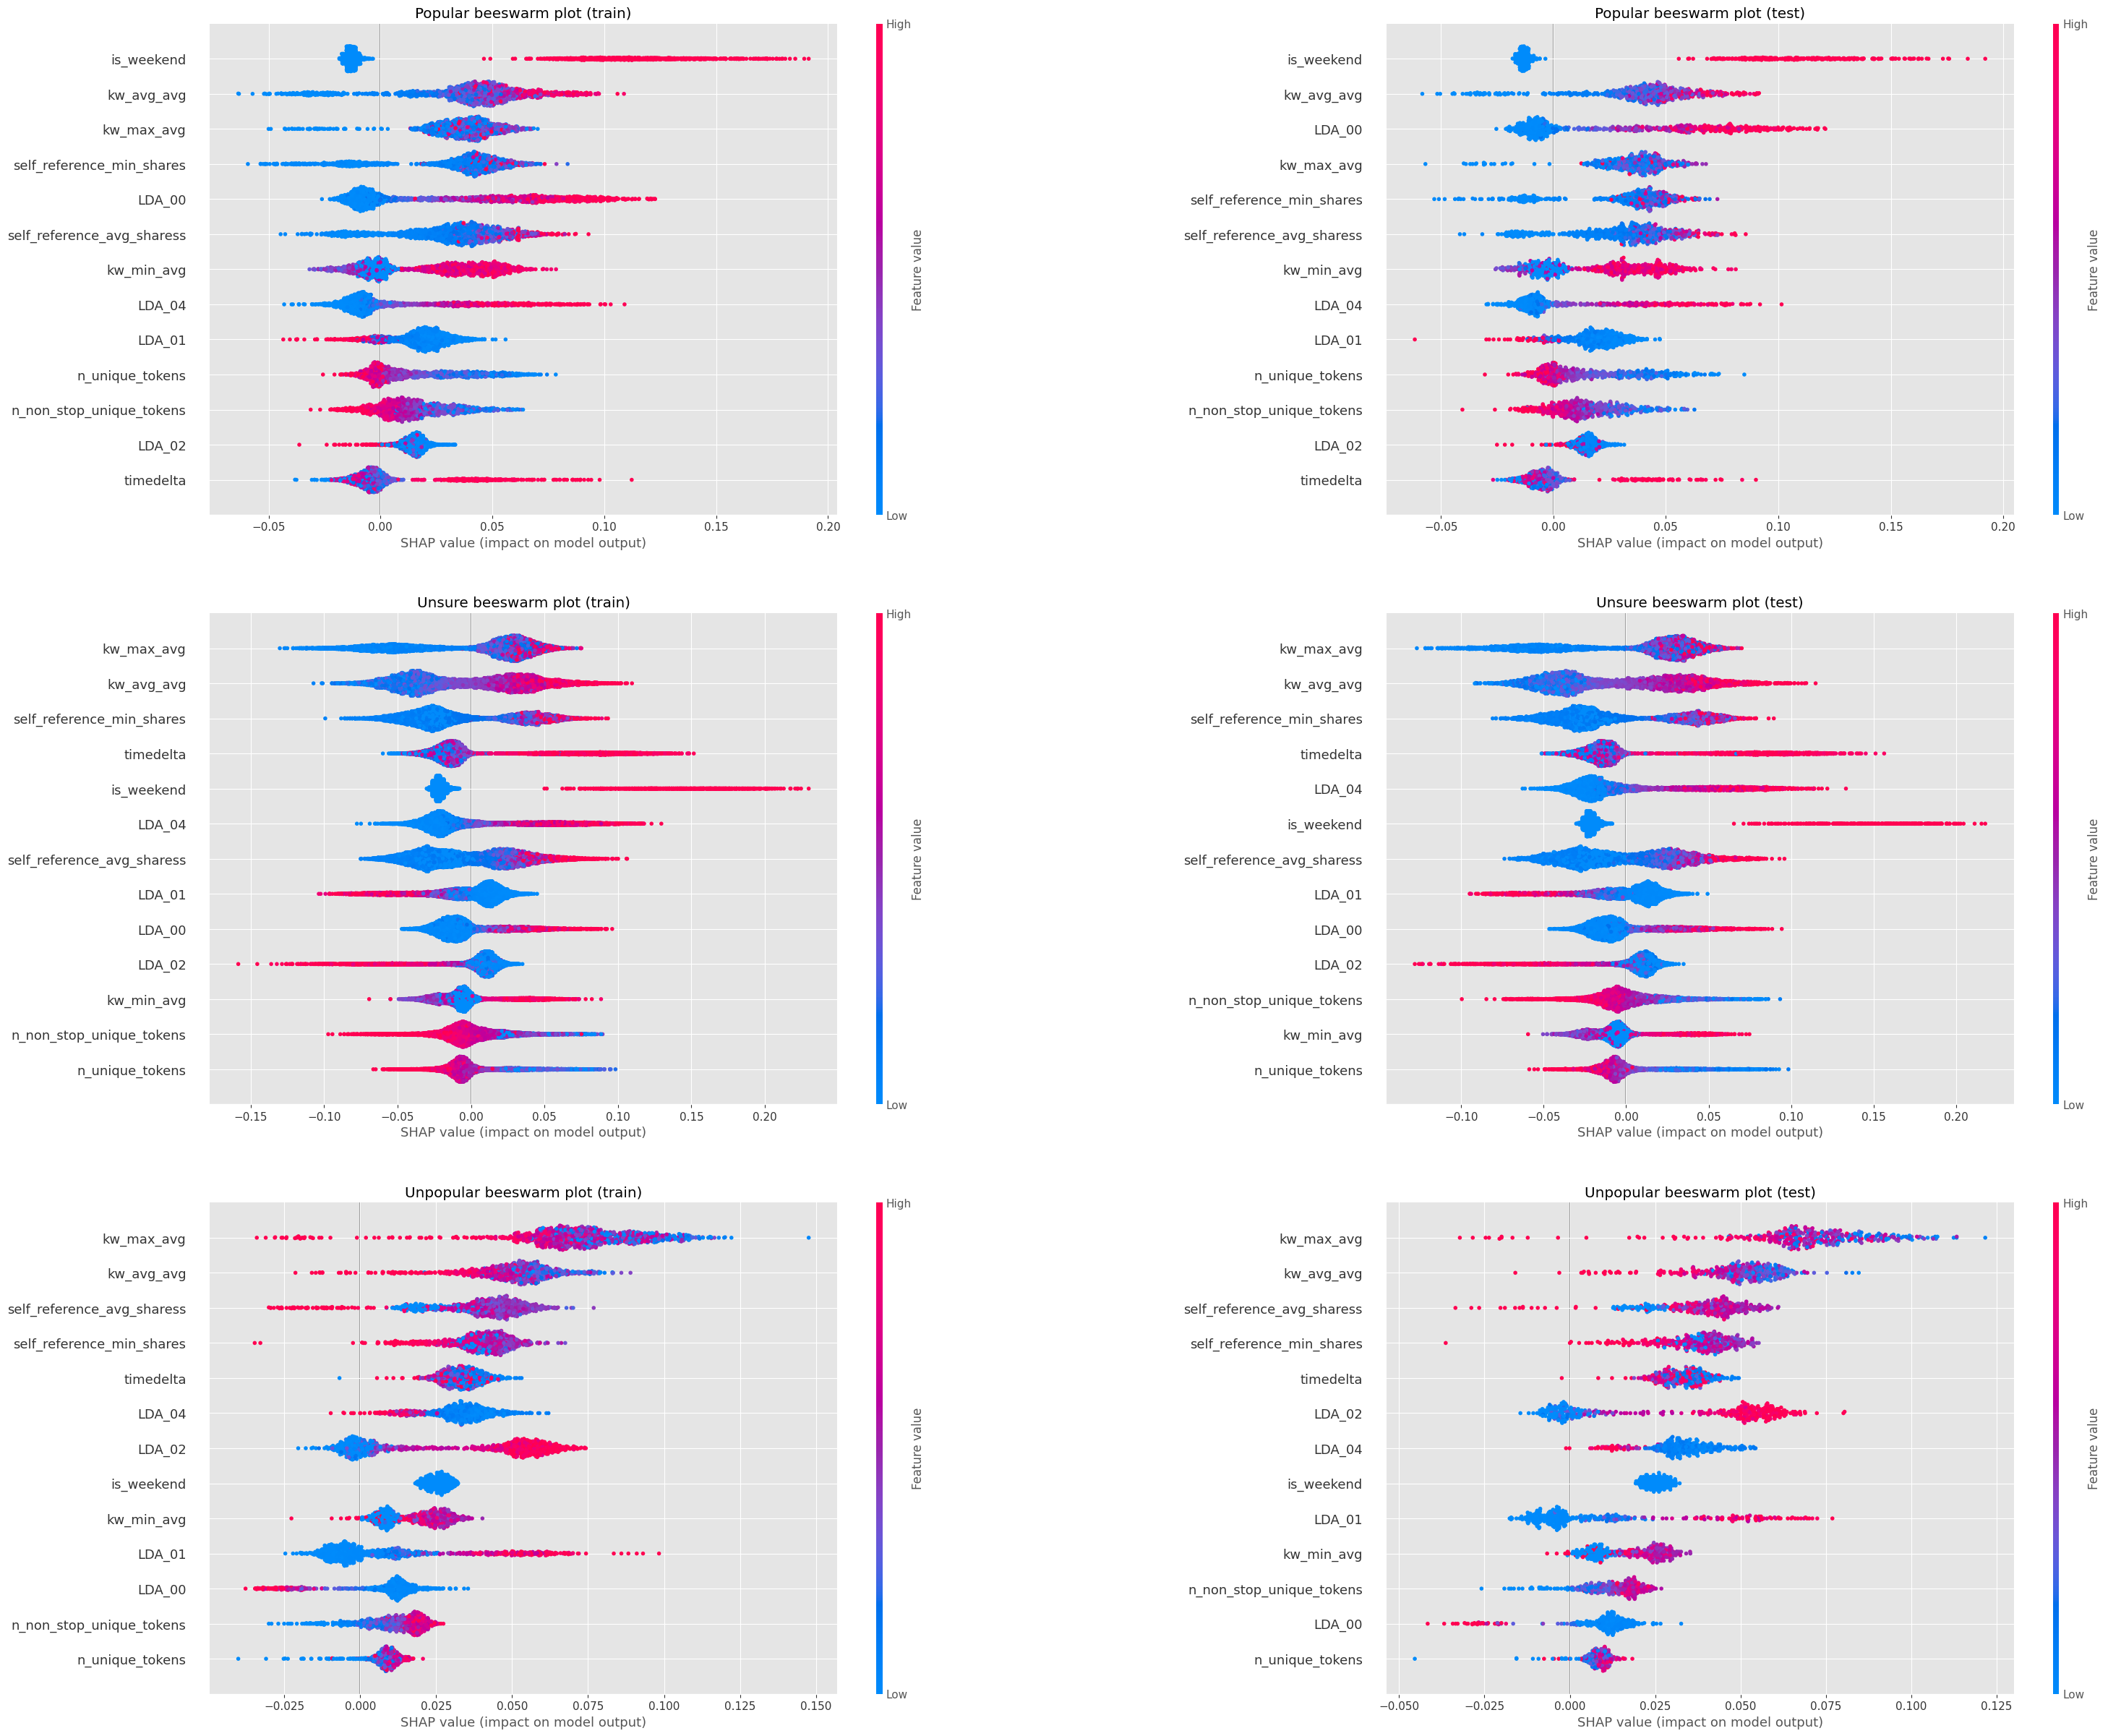

In [233]:
# Plot beeswarm plots for the 3 different classes of results
plt.figure(figsize=(35,30))

# Plot highly likely to be popular train
plt.subplot(3,2,1)
beeswarm(shap_values=shap_values_tr_pop[:,:,1],
         show=False,
         plot_size=None,
         max_display=13)
plt.gca().set_title('Popular beeswarm plot (train)')

# Plot highly likely to be popular test
plt.subplot(3,2,2)
beeswarm(shap_values=shap_values_tst_pop[:,:,1],
         show=False,
         plot_size=None,
         max_display=13)
plt.gca().set_title('Popular beeswarm plot (test)')


# Plot unsure about popularity train
plt.subplot(3,2,3)
beeswarm(shap_values=shap_values_tr_uns[:,:,1],
         show=False,
         plot_size=None,
         max_display=13)
plt.gca().set_title('Unsure beeswarm plot (train)')

# Plot unsure about popularity test
plt.subplot(3,2,4)
beeswarm(shap_values=shap_values_tst_uns[:,:,1],
         show=False,
         plot_size=None,
         max_display=13)
plt.gca().set_title('Unsure beeswarm plot (test)')

# Plot highly likely to be unpopular train
plt.subplot(3,2,5)
beeswarm(shap_values=shap_values_tr_unp[:,:,0],
         show=False,
         plot_size=None,
         max_display=13)
plt.gca().set_title('Unpopular beeswarm plot (train)')

# Plot highly likely to be unpopular test
plt.subplot(3,2,6)
beeswarm(shap_values=shap_values_tst_unp[:,:,0],
         show=False,
         plot_size=None,
         max_display=13)
plt.gca().set_title('Unpopular beeswarm plot (test)')

plt.subplots_adjust(wspace=0.5)
plt.show()

In [118]:
X_train_pruned.describe()

,timedelta,n_unique_tokens,n_non_stop_unique_tokens,kw_min_avg,kw_max_avg,kw_avg_avg,self_reference_min_shares,self_reference_avg_sharess,LDA_00,LDA_01,LDA_02,LDA_04
count,27750.000000,27750.000000,27750.000000,27750.000000,27750.000000,27750.000000,27750.000000,27750.000000,27750.000000,27750.000000,27750.000000,27750.000000
mean,354.241766,0.529997,0.672135,1117.839012,5649.881738,3137.583582,3989.782001,6442.231855,0.184944,0.141834,0.216092,0.232858
std,214.303133,0.138186,0.155623,1138.939937,5982.063213,1302.757903,19452.797590,24318.244492,0.263228,0.220126,0.282256,0.288445
min,8.000000,0.000000,0.000000,-1.000000,0.000000,0.000000,0.000000,0.000000,0.018182,0.018182,0.018182,0.018183
25%,164.000000,0.470833,0.625410,0.000000,3565.337885,2384.727238,640.250000,987.575000,0.025052,0.025011,0.028571,0.028573
50%,338.000000,0.538700,0.690601,1024.679487,4356.223633,2870.405706,1200.000000,2200.000000,0.033396,0.033345,0.040003,0.040720
75%,542.000000,0.608289,0.754839,2063.460714,6019.196618,3600.724447,2700.000000,5200.000000,0.240565,0.151154,0.333716,0.397791
max,731.000000,1.000000,1.000000,3613.039819,298400.000000,37607.521654,690400.000000,690400.000000,0.920000,0.925947,0.919999,0.927191


In [114]:
def get_probability(timedelta: int=720,
                    n_unique_tokens: float=0.47,
                    n_non_stop_unique_tokens: float=0.62,
                    kw_min_avg: int=2065,
                    kw_max_avg: int=6020,
                    kw_avg_avg: int=3600,
                    self_reference_min_shares: int=2700,
                    self_reference_avg_sharess: int=5200,
                    is_weekend: int=1,
                    LDA_00: float=0.24,
                    LDA_01: float=0.025,
                    LDA_02: float=0.025,
                    LDA_04: float=0.40):
    
    return pruned_rfc.predict_proba(X=np.array([timedelta, n_unique_tokens, n_non_stop_unique_tokens, kw_min_avg,
                                                kw_max_avg, kw_avg_avg, self_reference_min_shares, self_reference_avg_sharess,
                                                is_weekend, LDA_00, LDA_01, LDA_02, LDA_04]).reshape(1,-1))[:,1]

In [121]:
get_probability(is_weekend=0, kw_avg_avg=2000)

X does not have valid feature names, but RandomForestClassifier was fitted with feature names


array([0.69782079])